# Cross-Tool Network Measurement Analysis
This notebook documents the complete analysis pipeline for comparing **perfSONAR, RIPE Atlas, and Grafana Synthetic Monitoring** from a common FABRIC DALL site-level environment. It retains the important successful outputs so a reader can inspect the workflow and results without reproducing the live measurements.

## Pipeline
1. Define a common 17-column schema and target/tool mappings.
2. Normalize RTT and traceroute measurements from each platform.
3. Generate per-tool normalized CSVs and integrate the common 24-hour dataset.
4. Validate counts, timestamps, success, RTT/loss, hop counts, paths, and per-hop RTT.
5. Analyze temporal stability, path variation, controlled impairment response, paired RTT differences, CDFs, and Bland–Altman agreement.
6. Save the final statistics tables and publication-ready figures included in this repository.

**Reproducibility note:** Live Grafana/OpenSearch collection cells require access credentials and an active deployment. The raw/normalized files and final integrated dataset are included so the normalization and analysis can be inspected and rerun offline.


In [1]:
import os
import pandas as pd

BASE_DIR = "cross_tool_analysis"
os.makedirs(BASE_DIR, exist_ok=True)

columns = [
    "timestamp",
    "tool",
    "source_site",
    "source_host",
    "target_name",
    "target_ip",
    "measurement_type",

    "rtt_ms",
    "rtt_min_ms",
    "rtt_max_ms",
    "rtt_stddev_ms",

    "packets_sent",
    "packets_received",
    "packet_loss_pct",

    "hop_count",
    "path",
    "success"
]

df = pd.DataFrame(columns=columns)

output_file = os.path.join(BASE_DIR, "normalized_measurements.csv")
df.to_csv(output_file, index=False)

print("Created:", output_file)
print("Columns:")
for c in columns:
    print("-", c)

Created: cross_tool_analysis/normalized_measurements.csv
Columns:
- timestamp
- tool
- source_site
- source_host
- target_name
- target_ip
- measurement_type
- rtt_ms
- rtt_min_ms
- rtt_max_ms
- rtt_stddev_ms
- packets_sent
- packets_received
- packet_loss_pct
- hop_count
- path
- success


In [2]:
targets = {
    "Dallas": "2620:0:860:201:208:80:152:244",
    "Seattle": "2604:e180:de08::5",
    "NYC": "2604:a880:800:10::a0:b001",
    "Google": "2001:4860:4860::8888",
    "Cloudflare": "2606:4700:4700::1111",
    "FABRIC-SEAT": "2001:400:a100:3080:f816:3eff:fe23:6116"
}

target_df = pd.DataFrame(
    targets.items(),
    columns=["target_name", "target_ip"]
)

target_df

,target_name,target_ip
0,Dallas,2620:0:860:201:208:80:152:244
1,Seattle,2604:e180:de08::5
2,NYC,2604:a880:800:10::a0:b001
3,Google,2001:4860:4860::8888
4,Cloudflare,2606:4700:4700::1111
5,FABRIC-SEAT,2001:400:a100:3080:f816:3eff:fe23:6116


In [3]:
target_file = os.path.join(BASE_DIR, "target_mapping.csv")
target_df.to_csv(target_file, index=False)

print("Created:", target_file)
print()
print(target_df)

Created: cross_tool_analysis/target_mapping.csv

   target_name                               target_ip
0       Dallas           2620:0:860:201:208:80:152:244
1      Seattle                       2604:e180:de08::5
2          NYC               2604:a880:800:10::a0:b001
3       Google                    2001:4860:4860::8888
4   Cloudflare                    2606:4700:4700::1111
5  FABRIC-SEAT  2001:400:a100:3080:f816:3eff:fe23:6116


In [4]:
tool_mapping = pd.DataFrame([
    {
        "tool": "perfSONAR",
        "source_site": "DALL",
        "source_host": "remote-DALL"
    },
    {
        "tool": "RIPE Atlas",
        "source_site": "DALL",
        "source_host": "probe-1018891"
    },
    {
        "tool": "Grafana",
        "source_site": "DALL",
        "source_host": "grafana-probe"
    }
])

tool_file = os.path.join(BASE_DIR, "tool_mapping.csv")
tool_mapping.to_csv(tool_file, index=False)

print("Created:", tool_file)
tool_mapping

Created: cross_tool_analysis/tool_mapping.csv


,tool,source_site,source_host
0,perfSONAR,DALL,remote-DALL
1,RIPE Atlas,DALL,probe-1018891
2,Grafana,DALL,grafana-probe


In [5]:
raw_dirs = {
    "perfSONAR": os.path.join(BASE_DIR, "raw_perfsonar"),
    "RIPE Atlas": os.path.join(BASE_DIR, "raw_ripe_atlas"),
    "Grafana": os.path.join(BASE_DIR, "raw_grafana")
}

for tool, path in raw_dirs.items():
    os.makedirs(path, exist_ok=True)
    print(f"{tool}: {path}")

perfSONAR: cross_tool_analysis/raw_perfsonar
RIPE Atlas: cross_tool_analysis/raw_ripe_atlas
Grafana: cross_tool_analysis/raw_grafana


## perfSONAR RTT Normalization


In [26]:
def normalize_perfsonar(records, target_name):
    rows = []

    for r in records:
        result = r.get("result", {})
        rtt = result.get("rtt", {})
        packets = result.get("packets", {})
        test = r.get("test", {})
        spec = test.get("spec", {})
        pscheduler = r.get("pscheduler", {})
        meta = r.get("meta", {})

        # perfSONAR RTT values are stored in seconds
        mean_rtt = rtt.get("mean")
        min_rtt = rtt.get("min")
        max_rtt = rtt.get("max")
        stddev_rtt = rtt.get("stddev")

        rows.append({
            "timestamp": pscheduler.get("start_time"),
            "tool": "perfSONAR",
            "source_site": "DALL",
            "source_host": meta.get("source", {}).get("hostname", "remote-DALL"),
            "target_name": target_name,
            "target_ip": spec.get("dest"),
            "measurement_type": test.get("type"),

            "rtt_ms": mean_rtt * 1000 if mean_rtt is not None else None,
            "rtt_min_ms": min_rtt * 1000 if min_rtt is not None else None,
            "rtt_max_ms": max_rtt * 1000 if max_rtt is not None else None,
            "rtt_stddev_ms": stddev_rtt * 1000 if stddev_rtt is not None else None,

            "packets_sent": packets.get("sent"),
            "packets_received": packets.get("received"),
            "packet_loss_pct": (
                packets.get("loss") * 100
                if packets.get("loss") is not None
                else None
            ),

            "hop_count": None,
            "path": None,
            "success": result.get("succeeded")
        })

    return pd.DataFrame(rows, columns=columns)

In [3]:
import json

with open("Dallas_rtt_sample.json", "r") as f:
    perfsonar_records = json.load(f)

perfsonar_df = normalize_perfsonar(
    perfsonar_records,
    target_name="RIPE-Dallas"
)

print(perfsonar_df.shape)
perfsonar_df.head()

(27, 17)


,timestamp,tool,source_site,source_host,target_name,target_ip,measurement_type,rtt_ms,rtt_min_ms,rtt_max_ms,rtt_stddev_ms,packets_sent,packets_received,packet_loss_pct,hop_count,path,success
0,2026-11-12T18:31:16+00:00,perfSONAR,DALL,remote-DALL,RIPE-Dallas,2620:0:860:201:208:80:152:244,rtt,2.181,1.886,3.254,0.536,5,5,0.0,None,None,True
1,2026-11-12T18:17:41+00:00,perfSONAR,DALL,remote-DALL,RIPE-Dallas,2620:0:860:201:208:80:152:244,rtt,2.352,2.014,3.413,0.532,5,5,0.0,None,None,True
2,2026-11-12T18:01:57+00:00,perfSONAR,DALL,remote-DALL,RIPE-Dallas,2620:0:860:201:208:80:152:244,rtt,2.294,1.967,3.446,0.576,5,5,0.0,None,None,True
3,2026-11-12T17:54:01+00:00,perfSONAR,DALL,remote-DALL,RIPE-Dallas,2620:0:860:201:208:80:152:244,rtt,2.270,1.967,3.106,0.422,5,5,0.0,None,None,True
4,2026-11-12T17:39:20+00:00,perfSONAR,DALL,remote-DALL,RIPE-Dallas,2620:0:860:201:208:80:152:244,rtt,1.983,1.883,2.243,0.133,5,5,0.0,None,None,True


## RIPE Atlas RTT Normalization


In [30]:
def normalize_ripe_atlas(records, target_name):
    rows = []

    for r in records:
        results = r.get("result", [])

        # Individual successful RTT replies
        rtts = [
            item.get("rtt")
            for item in results
            if isinstance(item, dict) and item.get("rtt") is not None
        ]

        sent = r.get("sent")
        received = r.get("rcvd")

        packet_loss_pct = None
        if sent not in (None, 0) and received is not None:
            packet_loss_pct = ((sent - received) / sent) * 100

        rows.append({
            "timestamp": pd.to_datetime(
                r.get("timestamp"),
                unit="s",
                utc=True
            ) if r.get("timestamp") is not None else None,

            "tool": "RIPE Atlas",
            "source_site": "DALL",
            "source_host": f"probe-{r.get('prb_id')}",
            "target_name": target_name,
            "target_ip": r.get("dst_addr"),
            "measurement_type": "rtt",

            # RIPE Atlas already stores RTT in milliseconds
            "rtt_ms": r.get("avg"),
            "rtt_min_ms": r.get("min"),
            "rtt_max_ms": r.get("max"),

            # Calculate stddev from individual RTT replies
            "rtt_stddev_ms": (
                pd.Series(rtts).std(ddof=0)
                if rtts
                else None
            ),

            "packets_sent": sent,
            "packets_received": received,
            "packet_loss_pct": packet_loss_pct,

            "hop_count": None,
            "path": None,
            "success": received > 0 if received is not None else None
        })

    return pd.DataFrame(rows, columns=columns)

In [6]:
import json

ripe_records = []

with open(
    "RIPE-Atlas-measurement-235836693-1794421560-to-1794507960.json",
    "r"
) as f:
    for line in f:
        line = line.strip()
        if line:
            ripe_records.append(json.loads(line))

print("Records:", len(ripe_records))
print(ripe_records[0].keys())

Records: 96
dict_keys(['fw', 'mver', 'lts', 'dst_name', 'af', 'dst_addr', 'src_addr', 'proto', 'ttl', 'size', 'result', 'dup', 'rcvd', 'sent', 'min', 'max', 'avg', 'msm_id', 'prb_id', 'timestamp', 'msm_name', 'from', 'type', 'group_id', 'step', 'stored_timestamp'])


In [7]:
ripe_df = normalize_ripe_atlas(
    ripe_records,
    target_name="RIPE-Dallas"
)

print(ripe_df.shape)
ripe_df.head()

(96, 17)


,timestamp,tool,source_site,source_host,target_name,target_ip,measurement_type,rtt_ms,rtt_min_ms,rtt_max_ms,rtt_stddev_ms,packets_sent,packets_received,packet_loss_pct,hop_count,path,success
0,2026-11-11 18:30:50+00:00,RIPE Atlas,DALL,probe-1018891,RIPE-Dallas,2620:0:860:201:208:80:152:244,rtt,3.458608,3.432959,3.477143,0.018726,3,3,0.0,None,None,True
1,2026-11-11 18:45:49+00:00,RIPE Atlas,DALL,probe-1018891,RIPE-Dallas,2620:0:860:201:208:80:152:244,rtt,3.357236,3.309736,3.447006,0.063513,3,3,0.0,None,None,True
2,2026-11-11 19:00:50+00:00,RIPE Atlas,DALL,probe-1018891,RIPE-Dallas,2620:0:860:201:208:80:152:244,rtt,3.391790,3.343960,3.473144,0.057821,3,3,0.0,None,None,True
3,2026-11-11 19:15:38+00:00,RIPE Atlas,DALL,probe-1018891,RIPE-Dallas,2620:0:860:201:208:80:152:244,rtt,3.385648,3.362064,3.415244,0.022123,3,3,0.0,None,None,True
4,2026-11-11 19:30:46+00:00,RIPE Atlas,DALL,probe-1018891,RIPE-Dallas,2620:0:860:201:208:80:152:244,rtt,3.353531,3.282938,3.416700,0.054860,3,3,0.0,None,None,True


## Grafana RTT Normalization


In [12]:
def normalize_grafana(
    df,
    target_name,
    target_ip,
    source_host="fabric-private-probe"
):
    normalized = pd.DataFrame()

    normalized["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)

    normalized["tool"] = "Grafana"
    normalized["source_site"] = "DALL"
    normalized["source_host"] = source_host

    normalized["target_name"] = target_name
    normalized["target_ip"] = target_ip
    normalized["measurement_type"] = "rtt"

    normalized["rtt_ms"] = None

    normalized["rtt_min_ms"] = (
        df["rtt_min_seconds"] * 1000
        if "rtt_min_seconds" in df.columns
        else None
    )

    normalized["rtt_max_ms"] = (
        df["rtt_max_seconds"] * 1000
        if "rtt_max_seconds" in df.columns
        else None
    )

    normalized["rtt_stddev_ms"] = (
        df["rtt_stddev_seconds"] * 1000
        if "rtt_stddev_seconds" in df.columns
        else None
    )

    normalized["packets_sent"] = (
        df["packets_sent"]
        if "packets_sent" in df.columns
        else None
    )

    normalized["packets_received"] = (
        df["packets_received"]
        if "packets_received" in df.columns
        else None
    )

    if (
        "packets_sent" in df.columns
        and "packets_received" in df.columns
    ):
        normalized["packet_loss_pct"] = (
            (df["packets_sent"] - df["packets_received"])
            / df["packets_sent"]
            * 100
        )
    else:
        normalized["packet_loss_pct"] = None

    normalized["hop_count"] = None
    normalized["path"] = None

    normalized["success"] = (
        df["success"].astype(bool)
        if "success" in df.columns
        else None
    )

    return normalized[columns]

In [10]:
import pandas as pd

max_df = pd.read_csv("Explore-data-2026-11-12 13_46_38.csv")
min_df = pd.read_csv("Explore-data-2026-11-12 13_56_33.csv")
std_df = pd.read_csv("Explore-data-2026-11-12 13_57_55.csv")

max_df = max_df.rename(columns={
    "Time": "timestamp",
    max_df.columns[1]: "rtt_max_seconds"
})

min_df = min_df.rename(columns={
    "Time": "timestamp",
    min_df.columns[1]: "rtt_min_seconds"
})

std_df = std_df.rename(columns={
    "Time": "timestamp",
    std_df.columns[1]: "rtt_stddev_seconds"
})

grafana_raw = (
    max_df
    .merge(min_df, on="timestamp", how="inner")
    .merge(std_df, on="timestamp", how="inner")
)

# Confirmed from your Grafana queries
grafana_raw["success"] = 1
grafana_raw["packets_sent"] = 3
grafana_raw["packets_received"] = 3

print(grafana_raw.shape)
grafana_raw.head()

(3, 7)


,timestamp,rtt_max_seconds,rtt_min_seconds,rtt_stddev_seconds,success,packets_sent,packets_received
0,2026-11-12 12:57:00,0.00116,0.000996,0.000072,1,3,3
1,2026-11-12 12:58:00,0.00116,0.000996,0.000072,1,3,3
2,2026-11-12 12:59:00,0.00116,0.000996,0.000072,1,3,3


In [9]:
import requests
from getpass import getpass

PROM_URL = "https://prometheus-prod-66-prod-us-east-3.grafana.net/api/prom"
PROM_USER = "3681855"

PROM_TOKEN = getpass("Paste Grafana metrics:read token: ")

query = 'probe_icmp_duration_rtt_min_seconds{job="DALL-to-Cloudflare-Ping"}'

resp = requests.get(
    f"{PROM_URL}/api/v1/query",
    params={"query": query},
    auth=(PROM_USER, PROM_TOKEN),
    timeout=30
)

print("HTTP:", resp.status_code)
print(resp.json())

Paste Grafana metrics:read token:  ········


HTTP: 200
{'status': 'success', 'data': {'resultType': 'vector', 'result': [{'metric': {'__name__': 'probe_icmp_duration_rtt_min_seconds', 'config_version': '1794350626784742144', 'environment': 'fabric', 'instance': '2606:4700:4700::1111', 'job': 'DALL-to-Cloudflare-Ping', 'probe': 'fabric-private-probe', 'project': 'previous stage'}, 'value': [1794676343.816, '0.000936773']}]}}


In [17]:
from datetime import datetime, timedelta, timezone
import pandas as pd
import requests

query = 'probe_icmp_duration_rtt_min_seconds{job="DALL-to-Cloudflare-Ping"}'

# Current UTC time rounded down to a 15-minute boundary
now = datetime.now(timezone.utc)

end_time = now.replace(
    minute=(now.minute // 15) * 15,
    second=0,
    microsecond=0
)

start_time = end_time - timedelta(hours=24)

resp = requests.get(
    f"{PROM_URL}/api/v1/query_range",
    params={
        "query": query,
        "start": start_time.timestamp(),
        "end": end_time.timestamp(),
        "step": 900       # 15 minutes
    },
    auth=(PROM_USER, PROM_TOKEN),
    timeout=30
)

data = resp.json()

print("HTTP:", resp.status_code)
print("Status:", data.get("status"))
print("Start:", start_time)
print("End:", end_time)

result = data["data"]["result"][0]

rows = [
    {
        "timestamp": pd.to_datetime(ts, unit="s", utc=True),
        "rtt_min_seconds": float(value)
    }
    for ts, value in result["values"]
]

grafana_min_24h = pd.DataFrame(rows)

print("Rows returned:", len(grafana_min_24h))
grafana_min_24h.head()

HTTP: 200
Status: success
Start: 2026-11-11 21:15:00+00:00
End: 2026-11-12 21:15:00+00:00
Rows returned: 97


,timestamp,rtt_min_seconds
0,2026-11-11 21:15:00+00:00,0.001100
1,2026-11-11 21:30:00+00:00,0.000943
2,2026-11-11 21:45:00+00:00,0.000952
3,2026-11-11 22:00:00+00:00,0.001047
4,2026-11-11 22:15:00+00:00,0.001162


In [18]:
from functools import reduce
import pandas as pd
import requests

metrics = {
    "rtt_min_seconds":
        'probe_icmp_duration_rtt_min_seconds{job="DALL-to-Cloudflare-Ping"}',

    "rtt_max_seconds":
        'probe_icmp_duration_rtt_max_seconds{job="DALL-to-Cloudflare-Ping"}',

    "rtt_stddev_seconds":
        'probe_icmp_duration_rtt_stddev_seconds{job="DALL-to-Cloudflare-Ping"}',

    "success":
        'probe_success{job="DALL-to-Cloudflare-Ping"}',

    "packets_sent":
        'probe_icmp_packets_sent_count{job="DALL-to-Cloudflare-Ping"}',

    "packets_received":
        'probe_icmp_packets_received_count{job="DALL-to-Cloudflare-Ping"}'
}

grafana_frames = []

for column_name, query in metrics.items():

    resp = requests.get(
        f"{PROM_URL}/api/v1/query_range",
        params={
            "query": query,
            "start": start_time.timestamp(),
            "end": end_time.timestamp(),
            "step": 900
        },
        auth=(PROM_USER, PROM_TOKEN),
        timeout=30
    )

    data = resp.json()

    print(column_name, "HTTP:", resp.status_code)

    result = data["data"]["result"][0]

    temp_df = pd.DataFrame(
        [
            {
                "timestamp": pd.to_datetime(ts, unit="s", utc=True),
                column_name: float(value)
            }
            for ts, value in result["values"]
        ]
    )

    grafana_frames.append(temp_df)

grafana_raw_24h = reduce(
    lambda left, right: pd.merge(
        left,
        right,
        on="timestamp",
        how="inner"
    ),
    grafana_frames
)

# Keep exactly 96 fifteen-minute points
grafana_raw_24h = (
    grafana_raw_24h
    .tail(96)
    .reset_index(drop=True)
)

print("\nShape:", grafana_raw_24h.shape)
grafana_raw_24h.head()

rtt_min_seconds HTTP: 200
rtt_max_seconds HTTP: 200
rtt_stddev_seconds HTTP: 200
success HTTP: 200
packets_sent HTTP: 200
packets_received HTTP: 200

Shape: (96, 7)


,timestamp,rtt_min_seconds,rtt_max_seconds,rtt_stddev_seconds,success,packets_sent,packets_received
0,2026-11-11 21:30:00+00:00,0.000943,0.001201,0.000106,1.0,3.0,3.0
1,2026-11-11 21:45:00+00:00,0.000952,0.001288,0.000150,1.0,3.0,3.0
2,2026-11-11 22:00:00+00:00,0.001047,0.001336,0.000129,1.0,3.0,3.0
3,2026-11-11 22:15:00+00:00,0.001162,0.001230,0.000028,1.0,3.0,3.0
4,2026-11-11 22:30:00+00:00,0.000893,0.001258,0.000156,1.0,3.0,3.0


In [20]:
grafana_df = normalize_grafana(
    grafana_raw_24h,
    target_name="Cloudflare",
    target_ip="2606:4700:4700::1111"
)

print(grafana_df.shape)
grafana_df.head(10)

(96, 17)


,timestamp,tool,source_site,source_host,target_name,target_ip,measurement_type,rtt_ms,rtt_min_ms,rtt_max_ms,rtt_stddev_ms,packets_sent,packets_received,packet_loss_pct,hop_count,path,success
0,2026-11-11 21:30:00+00:00,Grafana,DALL,fabric-private-probe,Cloudflare,2606:4700:4700::1111,rtt,None,0.942806,1.201292,0.106441,3.0,3.0,0.0,None,None,True
1,2026-11-11 21:45:00+00:00,Grafana,DALL,fabric-private-probe,Cloudflare,2606:4700:4700::1111,rtt,None,0.952143,1.287716,0.149573,3.0,3.0,0.0,None,None,True
2,2026-11-11 22:00:00+00:00,Grafana,DALL,fabric-private-probe,Cloudflare,2606:4700:4700::1111,rtt,None,1.047152,1.336286,0.129038,3.0,3.0,0.0,None,None,True
3,2026-11-11 22:15:00+00:00,Grafana,DALL,fabric-private-probe,Cloudflare,2606:4700:4700::1111,rtt,None,1.161528,1.230297,0.028172,3.0,3.0,0.0,None,None,True
4,2026-11-11 22:30:00+00:00,Grafana,DALL,fabric-private-probe,Cloudflare,2606:4700:4700::1111,rtt,None,0.892562,1.258380,0.156149,3.0,3.0,0.0,None,None,True
5,2026-11-11 22:45:00+00:00,Grafana,DALL,fabric-private-probe,Cloudflare,2606:4700:4700::1111,rtt,None,0.987710,1.196243,0.092853,3.0,3.0,0.0,None,None,True
6,2026-11-11 23:00:00+00:00,Grafana,DALL,fabric-private-probe,Cloudflare,2606:4700:4700::1111,rtt,None,1.015092,1.156167,0.066240,3.0,3.0,0.0,None,None,True
7,2026-11-11 23:15:00+00:00,Grafana,DALL,fabric-private-probe,Cloudflare,2606:4700:4700::1111,rtt,None,0.965508,1.462163,0.227318,3.0,3.0,0.0,None,None,True
8,2026-11-11 23:30:00+00:00,Grafana,DALL,fabric-private-probe,Cloudflare,2606:4700:4700::1111,rtt,None,0.926164,1.131872,0.084364,3.0,3.0,0.0,None,None,True
9,2026-11-11 23:45:00+00:00,Grafana,DALL,fabric-private-probe,Cloudflare,2606:4700:4700::1111,rtt,None,0.917048,1.259601,0.146047,3.0,3.0,0.0,None,None,True


In [21]:
import os

RAW_GRAFANA_DIR = os.path.join("cross_tool_analysis", "raw_grafana")
os.makedirs(RAW_GRAFANA_DIR, exist_ok=True)

raw_file = os.path.join(
    RAW_GRAFANA_DIR,
    "grafana_cloudflare_24h_raw.csv"
)

normalized_file = os.path.join(
    RAW_GRAFANA_DIR,
    "grafana_cloudflare_24h_normalized.csv"
)

grafana_raw_24h.to_csv(raw_file, index=False)
grafana_df.to_csv(normalized_file, index=False)

print("Saved raw:", raw_file)
print("Saved normalized:", normalized_file)

Saved raw: cross_tool_analysis/raw_grafana/grafana_cloudflare_24h_raw.csv
Saved normalized: cross_tool_analysis/raw_grafana/grafana_cloudflare_24h_normalized.csv


In [7]:
GRAFANA_TARGETS = {
    "RIPE-Dallas": {
        "job": "DALL-to-RIPE-Dallas-Ping",
        "ip": "2620:0:860:201:208:80:152:244"
    },
    "RIPE-Seattle": {
        "job": "DALL-to-RIPE-Seattle-Ping",
        "ip": "2604:e180:de08::5"
    },
    "RIPE-NYC": {
        "job": "DALL-to-RIPE-NYC-Ping",
        "ip": "2604:a880:800:10::a0:b001"
    },
    "Google": {
        "job": "DALL-to-Google-Ping",
        "ip": "2001:4860:4860::8888"
    },
    "Cloudflare": {
        "job": "DALL-to-Cloudflare-Ping",
        "ip": "2606:4700:4700::1111"
    },
    "FABRIC-SEAT": {
        "job": "DALL-to-FABRIC-SEAT-Ping",
        "ip": "2001:400:a100:3080:f816:3eff:fe23:6116"
    }
}

In [24]:
"""one reusable function that pulls all six ping metrics for any Grafana target over the same 24-hour window."""
from functools import reduce
import pandas as pd
import requests

def fetch_grafana_ping_24h(job_name, start_time, end_time):
    metrics = {
        "rtt_min_seconds":
            f'probe_icmp_duration_rtt_min_seconds{{job="{job_name}"}}',

        "rtt_max_seconds":
            f'probe_icmp_duration_rtt_max_seconds{{job="{job_name}"}}',

        "rtt_stddev_seconds":
            f'probe_icmp_duration_rtt_stddev_seconds{{job="{job_name}"}}',

        "success":
            f'probe_success{{job="{job_name}"}}',

        "packets_sent":
            f'probe_icmp_packets_sent_count{{job="{job_name}"}}',

        "packets_received":
            f'probe_icmp_packets_received_count{{job="{job_name}"}}'
    }

    frames = []

    for column_name, query in metrics.items():
        resp = requests.get(
            f"{PROM_URL}/api/v1/query_range",
            params={
                "query": query,
                "start": start_time.timestamp(),
                "end": end_time.timestamp(),
                "step": 900
            },
            auth=(PROM_USER, PROM_TOKEN),
            timeout=30
        )

        data = resp.json()

        if resp.status_code != 200:
            raise RuntimeError(
                f"{column_name} failed: HTTP {resp.status_code}"
            )

        results = data.get("data", {}).get("result", [])

        if not results:
            raise RuntimeError(
                f"No data returned for {column_name} / {job_name}"
            )

        temp_df = pd.DataFrame(
            [
                {
                    "timestamp": pd.to_datetime(ts, unit="s", utc=True),
                    column_name: float(value)
                }
                for ts, value in results[0]["values"]
            ]
        )

        frames.append(temp_df)

    combined = reduce(
        lambda left, right: pd.merge(
            left,
            right,
            on="timestamp",
            how="inner"
        ),
        frames
    )

    # Keep 96 points = 24 hours × 4 measurements/hour
    combined = combined.tail(96).reset_index(drop=True)

    return combined

In [26]:
"""all six Grafana ping targets automatically, normalize each one, and save both raw and normalized CSVs"""
import os
import pandas as pd

RAW_GRAFANA_DIR = os.path.join("cross_tool_analysis", "raw_grafana")
os.makedirs(RAW_GRAFANA_DIR, exist_ok=True)

all_grafana_normalized = []

for target_name, info in GRAFANA_TARGETS.items():
    print(f"\nProcessing {target_name}...")

    raw_df = fetch_grafana_ping_24h(
        job_name=info["job"],
        start_time=start_time,
        end_time=end_time
    )

    normalized_df = normalize_grafana(
        raw_df,
        target_name=target_name,
        target_ip=info["ip"]
    )

    safe_name = target_name.lower().replace("-", "_")

    raw_file = os.path.join(
        RAW_GRAFANA_DIR,
        f"grafana_{safe_name}_24h_raw.csv"
    )

    normalized_file = os.path.join(
        RAW_GRAFANA_DIR,
        f"grafana_{safe_name}_24h_normalized.csv"
    )

    raw_df.to_csv(raw_file, index=False)
    normalized_df.to_csv(normalized_file, index=False)

    all_grafana_normalized.append(normalized_df)

    print("Raw shape:", raw_df.shape)
    print("Normalized shape:", normalized_df.shape)
    print("Saved:", raw_file)
    print("Saved:", normalized_file)

grafana_all_ping = pd.concat(
    all_grafana_normalized,
    ignore_index=True
)

print("\nCombined Grafana ping shape:", grafana_all_ping.shape)
grafana_all_ping.head()


Processing RIPE-Dallas...
Raw shape: (96, 7)
Normalized shape: (96, 17)
Saved: cross_tool_analysis/raw_grafana/grafana_ripe_dallas_24h_raw.csv
Saved: cross_tool_analysis/raw_grafana/grafana_ripe_dallas_24h_normalized.csv

Processing RIPE-Seattle...
Raw shape: (96, 7)
Normalized shape: (96, 17)
Saved: cross_tool_analysis/raw_grafana/grafana_ripe_seattle_24h_raw.csv
Saved: cross_tool_analysis/raw_grafana/grafana_ripe_seattle_24h_normalized.csv

Processing RIPE-NYC...
Raw shape: (96, 7)
Normalized shape: (96, 17)
Saved: cross_tool_analysis/raw_grafana/grafana_ripe_nyc_24h_raw.csv
Saved: cross_tool_analysis/raw_grafana/grafana_ripe_nyc_24h_normalized.csv

Processing Google...
Raw shape: (96, 7)
Normalized shape: (96, 17)
Saved: cross_tool_analysis/raw_grafana/grafana_google_24h_raw.csv
Saved: cross_tool_analysis/raw_grafana/grafana_google_24h_normalized.csv

Processing Cloudflare...
Raw shape: (96, 7)
Normalized shape: (96, 17)
Saved: cross_tool_analysis/raw_grafana/grafana_cloudflare_24h

,timestamp,tool,source_site,source_host,target_name,target_ip,measurement_type,rtt_ms,rtt_min_ms,rtt_max_ms,rtt_stddev_ms,packets_sent,packets_received,packet_loss_pct,hop_count,path,success
0,2026-11-11 21:30:00+00:00,Grafana,DALL,fabric-private-probe,RIPE-Dallas,2620:0:860:201:208:80:152:244,rtt,None,1.977797,3.200819,0.551163,3.0,3.0,0.0,None,None,True
1,2026-11-11 21:45:00+00:00,Grafana,DALL,fabric-private-probe,RIPE-Dallas,2620:0:860:201:208:80:152:244,rtt,None,2.032669,3.465358,0.644781,3.0,3.0,0.0,None,None,True
2,2026-11-11 22:00:00+00:00,Grafana,DALL,fabric-private-probe,RIPE-Dallas,2620:0:860:201:208:80:152:244,rtt,None,2.006319,2.635745,0.267343,3.0,3.0,0.0,None,None,True
3,2026-11-11 22:15:00+00:00,Grafana,DALL,fabric-private-probe,RIPE-Dallas,2620:0:860:201:208:80:152:244,rtt,None,2.056133,3.254819,0.552784,3.0,3.0,0.0,None,None,True
4,2026-11-11 22:30:00+00:00,Grafana,DALL,fabric-private-probe,RIPE-Dallas,2620:0:860:201:208:80:152:244,rtt,None,2.037378,3.022934,0.454076,3.0,3.0,0.0,None,None,True


In [18]:
def build_grafana_traceroutes(hops_df):
    traces = []

    for trace_id, group in hops_df.groupby("traceroute_id"):
        g = group.sort_values("ttl").copy()

        hop_count = int(g["ttl"].max())

        # Preserve missing hops as "*"
        path_parts = []
        for _, row in g.iterrows():
            host = row["host"]

            if pd.isna(host) or str(host).strip() == "":
                path_parts.append("*")
            else:
                path_parts.append(str(host))

        path = " -> ".join(path_parts)

        # Trace timestamp = first hop timestamp
        trace_timestamp = g["timestamp"].min()

        # Overall traceroute success:
        # final TTL exists and final host responded
        final_row = g.loc[g["ttl"].idxmax()]
        success = not (
            pd.isna(final_row["host"])
            or str(final_row["host"]).strip() == ""
        )

        traces.append({
            "timestamp": trace_timestamp,
            "traceroute_id": trace_id,
            "hop_count": hop_count,
            "path": path,
            "success": success
        })

    return (
        pd.DataFrame(traces)
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

In [33]:
grafana_trace_runs["timestamp"] = pd.to_datetime(
    grafana_trace_runs["timestamp"],
    utc=True
).astype("datetime64[ns, UTC]")

grafana_trace_metrics["timestamp"] = pd.to_datetime(
    grafana_trace_metrics["timestamp"],
    utc=True
).astype("datetime64[ns, UTC]")

## Grafana Traceroute Collection and Normalization


In [16]:
GRAFANA_TRACE_TARGETS = {
    "RIPE-Dallas": {
        "job": "DALL-to-RIPE-Dallas-Traceroute",
        "ip": "2620:0:860:201:208:80:152:244"
    },
    "RIPE-Seattle": {
        "job": "DALL-to-RIPE-Seattle-Traceroute",
        "ip": "2604:e180:de08::5"
    },
    "RIPE-NYC": {
        "job": "DALL-to-RIPE-NYC-Traceroute",
        "ip": "2604:a880:800:10::a0:b001"
    },
    "Google": {
        "job": "DALL-to-Google-Traceroute",
        "ip": "2001:4860:4860::8888"
    },
    "Cloudflare": {
        "job": "DALL-to-Cloudflare-Traceroute",
        "ip": "2606:4700:4700::1111"
    },
    "FABRIC-SEAT": {
        "job": "DALL-to-FABRIC-SEAT-Traceroute",
        "ip": "2001:400:a100:3080:f816:3eff:fe23:6116"
    }
}

In [17]:
import re
import pandas as pd
import requests

def fetch_grafana_trace_hops(job_name, start_time, end_time):
    log_query = f'{{job="{job_name}"}} |= "TTL="'

    resp = requests.get(
        f"{LOKI_URL}/loki/api/v1/query_range",
        params={
            "query": log_query,
            "start": int(start_time.timestamp() * 1_000_000_000),
            "end": int(end_time.timestamp() * 1_000_000_000),
            "limit": 5000,
            "direction": "forward"
        },
        auth=(LOKI_USER, LOKI_TOKEN),
        timeout=30
    )

    data = resp.json()

    if resp.status_code != 200:
        raise RuntimeError(
            f"{job_name} Loki query failed: HTTP {resp.status_code}"
        )

    rows = []

    pattern = re.compile(
        r'Hosts=(.*?)\s+TTL=(\d+)\s+ElapsedTime=([^\s]+)\s+'
        r'LossPercent=([0-9.]+)\s+Sent=(\d+)\s+TracerouteID=([^\s]+)'
    )

    for stream in data.get("data", {}).get("result", []):
        for ts_ns, line in stream.get("values", []):
            match = pattern.search(line)

            if match:
                hosts, ttl, elapsed, loss, sent, trace_id = match.groups()

                rows.append({
                    "timestamp": pd.to_datetime(
                        int(ts_ns),
                        unit="ns",
                        utc=True
                    ),
                    "traceroute_id": trace_id,
                    "ttl": int(ttl),
                    "host": hosts if hosts else None,
                    "elapsed_time": elapsed,
                    "loss_percent": float(loss),
                    "sent": int(sent)
                })

    return pd.DataFrame(rows)

In [22]:
from functools import reduce

def fetch_grafana_trace_metrics(job_name, start_time, end_time):
    metrics = {
        "prom_hop_count":
            f'probe_traceroute_total_hops{{job="{job_name}"}}',

        "trace_loss_fraction":
            f'probe_traceroute_packet_loss_percent{{job="{job_name}"}}',

        "route_hash":
            f'probe_traceroute_route_hash{{job="{job_name}"}}',

        "success_metric":
            f'probe_success{{job="{job_name}"}}'
    }

    frames = []

    for column_name, query in metrics.items():
        resp = requests.get(
            f"{PROM_URL}/api/v1/query_range",
            params={
                "query": query,
                "start": start_time.timestamp(),
                "end": end_time.timestamp(),
                "step": 900
            },
            auth=(PROM_USER, PROM_TOKEN),
            timeout=30
        )

        results = resp.json().get("data", {}).get("result", [])

        if not results:
            raise RuntimeError(
                f"No Prometheus data for {column_name} / {job_name}"
            )

        temp_df = pd.DataFrame([
            {
                "timestamp": pd.to_datetime(
                    ts,
                    unit="s",
                    utc=True
                ).as_unit("ns"),
                column_name: float(value)
            }
            for ts, value in results[0]["values"]
        ])

        frames.append(temp_df)

    combined = reduce(
        lambda left, right: pd.merge(
            left,
            right,
            on="timestamp",
            how="inner"
        ),
        frames
    )

    return combined.tail(96).reset_index(drop=True)

In [44]:
grafana_all = pd.concat(
    [
        grafana_all_ping,
        grafana_all_trace
    ],
    ignore_index=True
)

grafana_all_file = os.path.join(
    "cross_tool_analysis",
    "grafana_all_normalized_24h.csv"
)

grafana_all.to_csv(
    grafana_all_file,
    index=False
)

print("Combined Grafana shape:", grafana_all.shape)
print("Saved:", grafana_all_file)

Combined Grafana shape: (1152, 17)
Saved: cross_tool_analysis/grafana_all_normalized_24h.csv


In [45]:
import os

BASE_GRAFANA = os.path.join(
    "cross_tool_analysis",
    "raw_grafana"
)

PING_RAW = os.path.join(
    BASE_GRAFANA,
    "ping",
    "raw"
)

PING_NORM = os.path.join(
    BASE_GRAFANA,
    "ping",
    "normalized"
)

TRACE_COMPLETE = os.path.join(
    BASE_GRAFANA,
    "traceroute",
    "complete"
)

TRACE_NORM = os.path.join(
    BASE_GRAFANA,
    "traceroute",
    "normalized"
)

for folder in [
    PING_RAW,
    PING_NORM,
    TRACE_COMPLETE,
    TRACE_NORM
]:
    os.makedirs(folder, exist_ok=True)

print("Folders created.")

Folders created.


## perfSONAR Traceroute Normalization


In [53]:
import json
import pandas as pd
from pathlib import Path

TRACE_RAW_DIR = Path(
    "cross_tool_analysis/raw_perfsonar/traceroute/raw"
)

TRACE_NORM_DIR = Path(
    "cross_tool_analysis/raw_perfsonar/traceroute/normalized"
)

TRACE_NORM_DIR.mkdir(
    parents=True,
    exist_ok=True
)

PERFSONAR_TRACE_FILES = {
    "RIPE-Dallas":
        "perfsonar_ripe_dallas_traceroute_common_window_raw.json",

    "RIPE-Seattle":
        "perfsonar_ripe_seattle_traceroute_common_window_raw.json",

    "RIPE-NYC":
        "perfsonar_ripe_nyc_traceroute_common_window_raw.json",

    "Google":
        "perfsonar_google_traceroute_common_window_raw.json",

    "Cloudflare":
        "perfsonar_cloudflare_traceroute_common_window_raw.json",

    "FABRIC-SEAT":
        "perfsonar_fabric_seat_traceroute_common_window_raw.json"
}

all_perfsonar_trace = []

for target_name, filename in PERFSONAR_TRACE_FILES.items():

    file_path = TRACE_RAW_DIR / filename

    with open(file_path, "r") as f:
        records = json.load(f)

    normalized = normalize_perfsonar_traceroute(
        records,
        target_name
    )

    safe_name = target_name.lower().replace("-", "_")

    output_file = (
        TRACE_NORM_DIR
        / f"perfsonar_{safe_name}_traceroute_common_window_normalized.csv"
    )

    normalized.to_csv(
        output_file,
        index=False
    )

    all_perfsonar_trace.append(normalized)

    print(
        target_name,
        "| Raw:", len(records),
        "| Normalized:", normalized.shape
    )

perfsonar_all_trace = pd.concat(
    all_perfsonar_trace,
    ignore_index=True
)

print(
    "\nCombined perfSONAR traceroute shape:",
    perfsonar_all_trace.shape
)

RIPE-Dallas | Raw: 85 | Normalized: (85, 17)
RIPE-Seattle | Raw: 85 | Normalized: (85, 17)
RIPE-NYC | Raw: 85 | Normalized: (85, 17)
Google | Raw: 86 | Normalized: (86, 17)
Cloudflare | Raw: 86 | Normalized: (86, 17)
FABRIC-SEAT | Raw: 85 | Normalized: (85, 17)

Combined perfSONAR traceroute shape: (512, 17)


In [54]:
print("Shape:", perfsonar_all_trace.shape)

print("\nTargets:")
print(perfsonar_all_trace["target_name"].value_counts())

print("\nMeasurement types:")
print(perfsonar_all_trace["measurement_type"].value_counts())

print("\nSuccess counts:")
print(perfsonar_all_trace["success"].value_counts(dropna=False))

print("\nMissing hop_count:")
print(perfsonar_all_trace["hop_count"].isna().sum())

print("\nMissing path:")
print(perfsonar_all_trace["path"].isna().sum())

print("\nTimestamp range:")
print(perfsonar_all_trace["timestamp"].min())
print(perfsonar_all_trace["timestamp"].max())

Shape: (512, 17)

Targets:
target_name
Google          86
Cloudflare      86
RIPE-Dallas     85
RIPE-Seattle    85
RIPE-NYC        85
FABRIC-SEAT     85
Name: count, dtype: int64

Measurement types:
measurement_type
traceroute    512
Name: count, dtype: int64

Success counts:
success
True    512
Name: count, dtype: int64

Missing hop_count:
0

Missing path:
0

Timestamp range:
2026-11-11T21:15:00+00:00
2026-11-12T18:24:01+00:00


In [55]:
import json
import pandas as pd
from pathlib import Path

RTT_RAW_DIR = Path(
    "cross_tool_analysis/raw_perfsonar/ping/raw"
)

RTT_NORM_DIR = Path(
    "cross_tool_analysis/raw_perfsonar/ping/normalized"
)

RTT_NORM_DIR.mkdir(
    parents=True,
    exist_ok=True
)

PERFSONAR_RTT_FILES = {
    "RIPE-Dallas":
        "perfsonar_ripe_dallas_rtt_common_window_raw.json",

    "RIPE-Seattle":
        "perfsonar_ripe_seattle_rtt_common_window_raw.json",

    "RIPE-NYC":
        "perfsonar_ripe_nyc_rtt_common_window_raw.json",

    "Google":
        "perfsonar_google_rtt_common_window_raw.json",

    "Cloudflare":
        "perfsonar_cloudflare_rtt_common_window_raw.json",

    "FABRIC-SEAT":
        "perfsonar_fabric_seat_rtt_common_window_raw.json"
}

all_perfsonar_rtt = []

for target_name, filename in PERFSONAR_RTT_FILES.items():

    file_path = RTT_RAW_DIR / filename

    with open(file_path, "r") as f:
        records = json.load(f)

    normalized = normalize_perfsonar(
        records,
        target_name
    )

    safe_name = target_name.lower().replace("-", "_")

    output_file = (
        RTT_NORM_DIR
        / f"perfsonar_{safe_name}_rtt_common_window_normalized.csv"
    )

    normalized.to_csv(
        output_file,
        index=False
    )

    all_perfsonar_rtt.append(normalized)

    print(
        target_name,
        "| Raw:", len(records),
        "| Normalized:", normalized.shape
    )

perfsonar_all_rtt = pd.concat(
    all_perfsonar_rtt,
    ignore_index=True
)

print(
    "\nCombined perfSONAR RTT shape:",
    perfsonar_all_rtt.shape
)

RIPE-Dallas | Raw: 85 | Normalized: (85, 17)
RIPE-Seattle | Raw: 85 | Normalized: (85, 17)
RIPE-NYC | Raw: 85 | Normalized: (85, 17)
Google | Raw: 85 | Normalized: (85, 17)
Cloudflare | Raw: 85 | Normalized: (85, 17)
FABRIC-SEAT | Raw: 85 | Normalized: (85, 17)

Combined perfSONAR RTT shape: (510, 17)


In [56]:
print("Shape:", perfsonar_all_rtt.shape)

print("\nTargets:")
print(perfsonar_all_rtt["target_name"].value_counts())

print("\nMeasurement types:")
print(perfsonar_all_rtt["measurement_type"].value_counts())

print("\nSuccess counts:")
print(perfsonar_all_rtt["success"].value_counts(dropna=False))

print("\nMissing values:")
print(
    perfsonar_all_rtt[
        [
            "rtt_ms",
            "rtt_min_ms",
            "rtt_max_ms",
            "rtt_stddev_ms",
            "packets_sent",
            "packets_received",
            "packet_loss_pct"
        ]
    ].isna().sum()
)

print("\nTimestamp range:")
print(perfsonar_all_rtt["timestamp"].min())
print(perfsonar_all_rtt["timestamp"].max())

print("\nRTT summary by target (ms):")
print(
    perfsonar_all_rtt.groupby("target_name")[
        ["rtt_ms", "rtt_min_ms", "rtt_max_ms", "rtt_stddev_ms"]
    ]
    .agg(["count", "mean", "min", "max"])
    .round(3)
)

print("\nPacket loss summary:")
print(
    perfsonar_all_rtt.groupby("target_name")[
        "packet_loss_pct"
    ].agg(["count", "mean", "min", "max"])
)

Shape: (510, 17)

Targets:
target_name
RIPE-Dallas     85
RIPE-Seattle    85
RIPE-NYC        85
Google          85
Cloudflare      85
FABRIC-SEAT     85
Name: count, dtype: int64

Measurement types:
measurement_type
rtt    510
Name: count, dtype: int64

Success counts:
success
True    510
Name: count, dtype: int64

Missing values:
rtt_ms              0
rtt_min_ms          0
rtt_max_ms          0
rtt_stddev_ms       0
packets_sent        0
packets_received    0
packet_loss_pct     0
dtype: int64

Timestamp range:
2026-11-11T21:16:52+00:00
2026-11-12T18:25:27+00:00

RTT summary by target (ms):
             rtt_ms                         rtt_min_ms                  \
              count    mean     min     max      count    mean     min   
target_name                                                              
Cloudflare       85   1.608   1.305   1.930         85   1.292   1.138   
FABRIC-SEAT      85  45.753  45.292  46.133         85  45.237  45.117   
Google           85  20.840  20

In [57]:
perfsonar_all = pd.concat(
    [
        perfsonar_all_rtt,
        perfsonar_all_trace
    ],
    ignore_index=True
)

print("Combined perfSONAR shape:", perfsonar_all.shape)

print("\nMeasurement types:")
print(perfsonar_all["measurement_type"].value_counts())

print("\nTargets:")
print(
    perfsonar_all.groupby(
        ["target_name", "measurement_type"]
    ).size()
)

# Save final normalized perfSONAR dataset
perfsonar_all_file = (
    "cross_tool_analysis/"
    "perfsonar_all_normalized_common_window.csv"
)

perfsonar_all.to_csv(
    perfsonar_all_file,
    index=False
)

print("\nSaved:", perfsonar_all_file)

Combined perfSONAR shape: (1022, 17)

Measurement types:
measurement_type
traceroute    512
rtt           510
Name: count, dtype: int64

Targets:
target_name   measurement_type
Cloudflare    rtt                 85
              traceroute          86
FABRIC-SEAT   rtt                 85
              traceroute          85
Google        rtt                 85
              traceroute          86
RIPE-Dallas   rtt                 85
              traceroute          85
RIPE-NYC      rtt                 85
              traceroute          85
RIPE-Seattle  rtt                 85
              traceroute          85
dtype: int64

Saved: cross_tool_analysis/perfsonar_all_normalized_common_window.csv


## Final Common 24-Hour Window


In [1]:
import pandas as pd

COMMON_START = pd.Timestamp("2026-11-13 00:45:00", tz="UTC")
COMMON_END   = pd.Timestamp("2026-11-14 00:45:00", tz="UTC")

print("Grafana final window:")
print("Start:", COMMON_START)
print("End:  ", COMMON_END)

Grafana final window:
Start: 2026-11-13 00:45:00+00:00
End:   2026-11-14 00:45:00+00:00


In [5]:
from functools import reduce
import pandas as pd
import requests

def fetch_grafana_ping_final(job_name, start_time, end_time):

    metrics = {
        "rtt_min_seconds":
            f'probe_icmp_duration_rtt_min_seconds{{job="{job_name}"}}',

        "rtt_max_seconds":
            f'probe_icmp_duration_rtt_max_seconds{{job="{job_name}"}}',

        "rtt_stddev_seconds":
            f'probe_icmp_duration_rtt_stddev_seconds{{job="{job_name}"}}',

        "success":
            f'probe_success{{job="{job_name}"}}',

        "packets_sent":
            f'probe_icmp_packets_sent_count{{job="{job_name}"}}',

        "packets_received":
            f'probe_icmp_packets_received_count{{job="{job_name}"}}'
    }

    frames = []

    for column_name, query in metrics.items():

        resp = requests.get(
            f"{PROM_URL}/api/v1/query_range",
            params={
                "query": query,
                "start": start_time.timestamp(),
                "end": end_time.timestamp(),
                "step": 900
            },
            auth=(PROM_USER, PROM_TOKEN),
            timeout=30
        )

        if resp.status_code != 200:
            raise RuntimeError(
                f"{column_name} failed: HTTP {resp.status_code}"
            )

        data = resp.json()
        results = data.get("data", {}).get("result", [])

        if not results:
            raise RuntimeError(
                f"No data returned for {column_name} / {job_name}"
            )

        temp_df = pd.DataFrame(
            [
                {
                    "timestamp": pd.to_datetime(
                        ts,
                        unit="s",
                        utc=True
                    ),
                    column_name: float(value)
                }
                for ts, value in results[0]["values"]
            ]
        )

        frames.append(temp_df)

    combined = reduce(
        lambda left, right: pd.merge(
            left,
            right,
            on="timestamp",
            how="inner"
        ),
        frames
    )

    # Final common-window convention:
    # include start, exclude end
    combined = combined[
        (combined["timestamp"] >= start_time) &
        (combined["timestamp"] < end_time)
    ].copy()

    combined = combined.sort_values(
        "timestamp"
    ).reset_index(drop=True)

    return combined

In [14]:
columns = [
    "timestamp",
    "tool",
    "source_site",
    "source_host",
    "target_name",
    "target_ip",
    "measurement_type",
    "rtt_ms",
    "rtt_min_ms",
    "rtt_max_ms",
    "rtt_stddev_ms",
    "packets_sent",
    "packets_received",
    "packet_loss_pct",
    "hop_count",
    "path",
    "success"
]

print("Columns loaded:", len(columns))

Columns loaded: 17


In [15]:
import os
import pandas as pd

FINAL_GRAFANA_DIR = os.path.join(
    "cross_tool_analysis",
    "raw_grafana",
    "final_24h"
)
os.makedirs(FINAL_GRAFANA_DIR, exist_ok=True)

all_grafana_ping_final = []

for target_name, info in GRAFANA_TARGETS.items():

    print(f"\nProcessing {target_name}...")

    raw_df = fetch_grafana_ping_final(
        job_name=info["job"],
        start_time=COMMON_START,
        end_time=COMMON_END
    )

    normalized_df = normalize_grafana(
        raw_df,
        target_name=target_name,
        target_ip=info["ip"]
    )

    safe_name = target_name.lower().replace("-", "_")

    raw_file = os.path.join(
        FINAL_GRAFANA_DIR,
        f"grafana_{safe_name}_ping_final_24h_raw.csv"
    )

    normalized_file = os.path.join(
        FINAL_GRAFANA_DIR,
        f"grafana_{safe_name}_ping_final_24h_normalized.csv"
    )

    raw_df.to_csv(raw_file, index=False)
    normalized_df.to_csv(normalized_file, index=False)

    all_grafana_ping_final.append(normalized_df)

    print("Raw shape:", raw_df.shape)
    print("Normalized shape:", normalized_df.shape)
    print("First:", raw_df["timestamp"].min())
    print("Last: ", raw_df["timestamp"].max())


grafana_ping_final = pd.concat(
    all_grafana_ping_final,
    ignore_index=True
)

print("\nCombined Grafana ping shape:", grafana_ping_final.shape)


Processing RIPE-Dallas...
Raw shape: (96, 7)
Normalized shape: (96, 17)
First: 2026-11-13 00:45:00+00:00
Last:  2026-11-14 00:30:00+00:00

Processing RIPE-Seattle...
Raw shape: (96, 7)
Normalized shape: (96, 17)
First: 2026-11-13 00:45:00+00:00
Last:  2026-11-14 00:30:00+00:00

Processing RIPE-NYC...
Raw shape: (96, 7)
Normalized shape: (96, 17)
First: 2026-11-13 00:45:00+00:00
Last:  2026-11-14 00:30:00+00:00

Processing Google...
Raw shape: (96, 7)
Normalized shape: (96, 17)
First: 2026-11-13 00:45:00+00:00
Last:  2026-11-14 00:30:00+00:00

Processing Cloudflare...
Raw shape: (96, 7)
Normalized shape: (96, 17)
First: 2026-11-13 00:45:00+00:00
Last:  2026-11-14 00:30:00+00:00

Processing FABRIC-SEAT...
Raw shape: (96, 7)
Normalized shape: (96, 17)
First: 2026-11-13 00:45:00+00:00
Last:  2026-11-14 00:30:00+00:00

Combined Grafana ping shape: (576, 17)


In [28]:
import json
import pandas as pd
from pathlib import Path

PERF_RTT_FINAL_DIR = Path(
    "cross_tool_analysis/raw_perfsonar/ping/raw_final_24h"
)

PERF_RTT_FILES = {
    "RIPE-Dallas": "RIPE-Dallas_rtt_24h.json",
    "RIPE-Seattle": "RIPE-Seattle_rtt_24h.json",
    "RIPE-NYC": "RIPE-NYC_rtt_24h.json",
    "Google": "Google_rtt_24h.json",
    "Cloudflare": "Cloudflare_rtt_24h.json",
    "FABRIC-SEAT": "FABRIC-SEAT_rtt_24h.json",
}

all_perfsonar_rtt_final = []

for target_name, filename in PERF_RTT_FILES.items():

    file_path = PERF_RTT_FINAL_DIR / filename

    with open(file_path, "r") as f:
        records = json.load(f)

    normalized_df = normalize_perfsonar(
        records,
        target_name
    )

    all_perfsonar_rtt_final.append(normalized_df)

    print(
        target_name,
        "raw:", len(records),
        "normalized:", normalized_df.shape
    )

perfsonar_rtt_final = pd.concat(
    all_perfsonar_rtt_final,
    ignore_index=True
)

print("\nCombined perfSONAR RTT shape:",
      perfsonar_rtt_final.shape)

print("\nCounts by target:")
print(
    perfsonar_rtt_final["target_name"]
    .value_counts()
)

RIPE-Dallas raw: 96 normalized: (96, 17)
RIPE-Seattle raw: 96 normalized: (96, 17)
RIPE-NYC raw: 96 normalized: (96, 17)
Google raw: 97 normalized: (97, 17)
Cloudflare raw: 96 normalized: (96, 17)
FABRIC-SEAT raw: 96 normalized: (96, 17)

Combined perfSONAR RTT shape: (577, 17)

Counts by target:
target_name
Google          97
RIPE-Dallas     96
RIPE-Seattle    96
RIPE-NYC        96
Cloudflare      96
FABRIC-SEAT     96
Name: count, dtype: int64


## RIPE Atlas Final 24-Hour Normalization


In [35]:
RIPE_FINAL_FILES = {
    "RIPE-Dallas": {
        "ping": "RIPE-Atlas-measurement-235836693-1794501720-to-1794674520.json",
        "traceroute": "RIPE-Atlas-measurement-237106984-1794499980-to-1794672780.json",
    },

    "RIPE-Seattle": {
        "ping": "RIPE-Atlas-measurement-237099900-1794501720-to-1794674520.json",
        "traceroute": "RIPE-Atlas-measurement-237101104-1794501660-to-1794674460.json",
    },

    "RIPE-NYC": {
        "ping": "RIPE-Atlas-measurement-237101628-1794501660-to-1794674460.json",
        "traceroute": "RIPE-Atlas-measurement-237103053-1794500580-to-1794673380.json",
    },

    "Google": {
        "ping": "RIPE-Atlas-measurement-237103504-1794500580-to-1794673380.json",
        "traceroute": "RIPE-Atlas-measurement-237103629-1794500520-to-1794673320.json",
    },

    "Cloudflare": {
        "ping": "RIPE-Atlas-measurement-237104034-1794500460-to-1794673260.json",
        "traceroute": "RIPE-Atlas-measurement-237106377-1794500460-to-1794673260.json",
    },

    "FABRIC-SEAT": {
        "ping": "RIPE-Atlas-measurement-237106487-1794500400-to-1794673200.json",
        "traceroute": "RIPE-Atlas-measurement-237106712-1794500400-to-1794673200.json",
    },
}

In [34]:
from pathlib import Path

base = Path(".")

ripe_files = sorted(
    base.glob("RIPE-Atlas-measurement-*.json")
)

print("Total RIPE Atlas files:", len(ripe_files))

for p in ripe_files:
    print(p.name)

Total RIPE Atlas files: 13
RIPE-Atlas-measurement-235836693-1794421560-to-1794507960.json
RIPE-Atlas-measurement-235836693-1794501720-to-1794674520.json
RIPE-Atlas-measurement-237099900-1794501720-to-1794674520.json
RIPE-Atlas-measurement-237101104-1794501660-to-1794674460.json
RIPE-Atlas-measurement-237101628-1794501660-to-1794674460.json
RIPE-Atlas-measurement-237103053-1794500580-to-1794673380.json
RIPE-Atlas-measurement-237103504-1794500580-to-1794673380.json
RIPE-Atlas-measurement-237103629-1794500520-to-1794673320.json
RIPE-Atlas-measurement-237104034-1794500460-to-1794673260.json
RIPE-Atlas-measurement-237106377-1794500460-to-1794673260.json
RIPE-Atlas-measurement-237106487-1794500400-to-1794673200.json
RIPE-Atlas-measurement-237106712-1794500400-to-1794673200.json
RIPE-Atlas-measurement-237106984-1794499980-to-1794672780.json


In [36]:
import json
import pandas as pd
from pathlib import Path

RIPE_BASE = Path(
    "."
)

all_ripe_ping_final = []

for target_name, files in RIPE_FINAL_FILES.items():

    file_path = RIPE_BASE / files["ping"]

    records = []

    with open(file_path, "r") as f:
        content = f.read().strip()

        # RIPE exports may be either JSON array
        # or line-delimited JSON.
        if content.startswith("["):
            records = json.loads(content)
        else:
            for line in content.splitlines():
                line = line.strip()
                if line:
                    records.append(json.loads(line))

    # Keep only our final common 24-hour window
    filtered_records = []

    for r in records:
        ts = pd.to_datetime(
            r.get("timestamp"),
            unit="s",
            utc=True,
            errors="coerce"
        )

        if (
            pd.notna(ts)
            and ts >= COMMON_START
            and ts < COMMON_END
        ):
            filtered_records.append(r)

    normalized_df = normalize_ripe_atlas(
        filtered_records,
        target_name
    )

    all_ripe_ping_final.append(normalized_df)

    print(
        target_name,
        "| file records:", len(records),
        "| final-window:", len(filtered_records),
        "| normalized:", normalized_df.shape
    )

ripe_ping_final = pd.concat(
    all_ripe_ping_final,
    ignore_index=True
)

print(
    "\nCombined RIPE Atlas Ping/RTT shape:",
    ripe_ping_final.shape
)

print("\nCounts by target:")
print(
    ripe_ping_final["target_name"]
    .value_counts()
)

print("\nTimestamp range:")
print("First:", ripe_ping_final["timestamp"].min())
print("Last: ", ripe_ping_final["timestamp"].max())

RIPE-Dallas | file records: 192 | final-window: 96 | normalized: (96, 17)
RIPE-Seattle | file records: 162 | final-window: 96 | normalized: (96, 17)
RIPE-NYC | file records: 162 | final-window: 96 | normalized: (96, 17)
Google | file records: 160 | final-window: 96 | normalized: (96, 17)
Cloudflare | file records: 160 | final-window: 96 | normalized: (96, 17)
FABRIC-SEAT | file records: 159 | final-window: 96 | normalized: (96, 17)

Combined RIPE Atlas Ping/RTT shape: (576, 17)

Counts by target:
target_name
RIPE-Dallas     96
RIPE-Seattle    96
RIPE-NYC        96
Google          96
Cloudflare      96
FABRIC-SEAT     96
Name: count, dtype: int64

Timestamp range:
First: 2026-11-13 00:45:42+00:00
Last:  2026-11-14 00:44:43+00:00


In [37]:
import json
from pathlib import Path

trace_file = Path(
    ""
    "RIPE-Atlas-measurement-237106984-1794499980-to-1794672780.json"
)

with open(trace_file, "r") as f:
    content = f.read().strip()

    if content.startswith("["):
        trace_records = json.loads(content)
    else:
        trace_records = [
            json.loads(line)
            for line in content.splitlines()
            if line.strip()
        ]

print("Records:", len(trace_records))
print("\nTop-level keys:")
print(trace_records[0].keys())

print("\nFirst traceroute result:")
print(trace_records[0]["result"][:3])

Records: 159

Top-level keys:
dict_keys(['fw', 'mver', 'lts', 'endtime', 'dst_name', 'dst_addr', 'src_addr', 'proto', 'af', 'size', 'paris_id', 'result', 'destination_ip_responded', 'msm_id', 'prb_id', 'timestamp', 'msm_name', 'from', 'type', 'group_id', 'stored_timestamp'])

First traceroute result:
[{'hop': 1, 'result': [{'from': '2001:400:a100:3000::1', 'ttl': 64, 'rtt': 1.624, 'size': 96}, {'from': '2001:400:a100:3000::1', 'ttl': 64, 'rtt': 0.152, 'size': 96}, {'from': '2001:400:a100:3000::1', 'ttl': 64, 'rtt': 0.097, 'size': 96}]}, {'hop': 2, 'result': [{'from': '2001:400:a100:1000::1', 'ttl': 63, 'rtt': 0.368, 'size': 96}, {'from': '2001:400:a100:1000::1', 'ttl': 63, 'rtt': 0.286, 'size': 96}, {'from': '2001:400:a100:1000::1', 'ttl': 63, 'rtt': 0.266, 'size': 96}]}, {'hop': 3, 'result': [{'from': '2001:504:0:5:0:1:4907:1', 'ttl': 62, 'rtt': 0.55, 'size': 96}, {'from': '2001:504:0:5:0:1:4907:1', 'ttl': 62, 'rtt': 0.56, 'size': 96}, {'from': '2001:504:0:5:0:1:4907:1', 'ttl': 62, 'r

In [51]:
# """RIPE Atlas traceroute normalizer - final common 24h window"""

# def normalize_ripe_atlas_traceroute(
#     records,
#     target_name,
#     common_start=COMMON_START,
#     common_end=COMMON_END
# ):
#     rows = []

#     for r in records:

#         measurement_time = pd.to_datetime(
#             r.get("timestamp"),
#             unit="s",
#             utc=True,
#             errors="coerce"
#         )

#         # Keep only final common 24-hour window
#         if pd.isna(measurement_time):
#             continue

#         if not (
#             measurement_time >= common_start
#             and measurement_time < common_end
#         ):
#             continue

#         hop_results = r.get("result", [])

#         path_parts = []
#         hop_rtt_details = []

#         max_hop = 0
#         missing_hops = 0

#         for hop_entry in hop_results:

#             hop_number = hop_entry.get("hop")

#             if hop_number is not None:
#                 max_hop = max(max_hop, hop_number)

#             replies = hop_entry.get("result", [])

#             responding_ips = []
#             rtts = []

#             for reply in replies:
#                 if not isinstance(reply, dict):
#                     continue

#                 if reply.get("from"):
#                     responding_ips.append(reply.get("from"))

#                 if reply.get("rtt") is not None:
#                     rtts.append(reply.get("rtt"))

#             # Path representation
#             if responding_ips:
#                 # Use first responding IP for common path representation
#                 hop_ip = responding_ips[0]
#                 path_parts.append(hop_ip)
#             else:
#                 hop_ip = "*"
#                 path_parts.append("*")
#                 missing_hops += 1

#             # Preserve per-hop RTT detail for later analysis
#             hop_rtt_details.append({
#                 "hop": hop_number,
#                 "ip": hop_ip,
#                 "rtts_ms": rtts,
#                 "avg_rtt_ms": (
#                     sum(rtts) / len(rtts)
#                     if rtts
#                     else None
#                 )
#             })

#         path = " -> ".join(path_parts)

#         # For traceroute, this represents non-responsive hop positions,
#         # not ordinary ICMP ping packet loss.
#         trace_loss_pct = None

#         if max_hop > 0:
#             trace_loss_pct = (
#                 missing_hops / max_hop
#             ) * 100

#         rows.append({
#             "timestamp": measurement_time,

#             "tool": "RIPE Atlas",
#             "source_site": "DALL",
#             "source_host": f"probe-{r.get('prb_id')}",

#             "target_name": target_name,
#             "target_ip": r.get("dst_addr"),

#             "measurement_type": "traceroute",

#             "rtt_ms": None,
#             "rtt_min_ms": None,
#             "rtt_max_ms": None,
#             "rtt_stddev_ms": None,

#             "packets_sent": None,
#             "packets_received": None,

#             "packet_loss_pct": trace_loss_pct,

#             "hop_count": max_hop,
#             "path": path,

#             "success": r.get("destination_ip_responded")
#         })

#     df = pd.DataFrame(
#         rows,
#         columns=columns
#     )

#     if not df.empty:
#         df = (
#             df.sort_values("timestamp")
#             .reset_index(drop=True)
#         )

#     return df


"""RIPE Atlas traceroute normalizer - handles special TTL 255"""

def normalize_ripe_atlas_traceroute(
    records,
    target_name,
    common_start=COMMON_START,
    common_end=COMMON_END
):
    rows = []

    for r in records:

        measurement_time = pd.to_datetime(
            r.get("timestamp"),
            unit="s",
            utc=True,
            errors="coerce"
        )

        if pd.isna(measurement_time):
            continue

        if not (
            measurement_time >= common_start
            and measurement_time < common_end
        ):
            continue

        hop_results = r.get("result", [])
        destination = r.get("dst_addr")

        path_parts = []
        normal_hop_numbers = []
        destination_hop = None
        missing_hops = 0

        for hop_entry in hop_results:

            hop_number = hop_entry.get("hop")
            replies = hop_entry.get("result", [])

            responding_ips = []

            for reply in replies:
                if (
                    isinstance(reply, dict)
                    and reply.get("from")
                ):
                    responding_ips.append(
                        reply.get("from")
                    )

            if responding_ips:
                hop_ip = responding_ips[0]
                path_parts.append(hop_ip)

                if destination in responding_ips:
                    destination_hop = hop_number
            else:
                path_parts.append("*")
                missing_hops += 1

            # TTL 255 is a special terminal probe,
            # not a literal measured path length.
            if (
                hop_number is not None
                and hop_number != 255
            ):
                normal_hop_numbers.append(
                    hop_number
                )

        destination_responded = bool(
            r.get("destination_ip_responded")
        )

        # If destination was reached at normal TTL,
        # that TTL is the measured hop count.
        #
        # If destination only replied at TTL 255,
        # exact path length is unknown.
        if (
            destination_hop is not None
            and destination_hop != 255
        ):
            hop_count = destination_hop

        elif destination_hop == 255:
            hop_count = None

        else:
            hop_count = (
                max(normal_hop_numbers)
                if normal_hop_numbers
                else None
            )

        trace_loss_pct = None

        if normal_hop_numbers:
            trace_loss_pct = (
                missing_hops
                / len(normal_hop_numbers)
                * 100
            )

        rows.append({
            "timestamp": measurement_time,

            "tool": "RIPE Atlas",
            "source_site": "DALL",
            "source_host": f"probe-{r.get('prb_id')}",

            "target_name": target_name,
            "target_ip": destination,

            "measurement_type": "traceroute",

            "rtt_ms": None,
            "rtt_min_ms": None,
            "rtt_max_ms": None,
            "rtt_stddev_ms": None,

            "packets_sent": None,
            "packets_received": None,

            "packet_loss_pct": trace_loss_pct,

            "hop_count": hop_count,
            "path": " -> ".join(path_parts),

            "success": destination_responded
        })

    return pd.DataFrame(
        rows,
        columns=columns
    ).sort_values(
        "timestamp"
    ).reset_index(drop=True)

In [40]:
all_ripe_trace_final = []

for target_name, files in RIPE_FINAL_FILES.items():

    file_path = RIPE_BASE / files["traceroute"]

    with open(file_path, "r") as f:
        content = f.read().strip()

        if content.startswith("["):
            records = json.loads(content)
        else:
            records = [
                json.loads(line)
                for line in content.splitlines()
                if line.strip()
            ]

    normalized_df = normalize_ripe_atlas_traceroute(
        records,
        target_name
    )

    all_ripe_trace_final.append(normalized_df)

    print(
        target_name,
        "| file records:", len(records),
        "| normalized:", normalized_df.shape
    )

ripe_trace_final = pd.concat(
    all_ripe_trace_final,
    ignore_index=True
)

print(
    "\nCombined RIPE Atlas traceroute shape:",
    ripe_trace_final.shape
)

print("\nCounts by target:")
print(
    ripe_trace_final["target_name"]
    .value_counts()
)

print("\nTimestamp range:")
print("First:", ripe_trace_final["timestamp"].min())
print("Last: ", ripe_trace_final["timestamp"].max())

print("\nSuccess counts:")
print(
    ripe_trace_final["success"]
    .value_counts(dropna=False)
)

RIPE-Dallas | file records: 159 | normalized: (96, 17)
RIPE-Seattle | file records: 162 | normalized: (96, 17)
RIPE-NYC | file records: 160 | normalized: (96, 17)
Google | file records: 160 | normalized: (96, 17)
Cloudflare | file records: 159 | normalized: (96, 17)
FABRIC-SEAT | file records: 159 | normalized: (96, 17)

Combined RIPE Atlas traceroute shape: (576, 17)

Counts by target:
target_name
RIPE-Dallas     96
RIPE-Seattle    96
RIPE-NYC        96
Google          96
Cloudflare      96
FABRIC-SEAT     96
Name: count, dtype: int64

Timestamp range:
First: 2026-11-13 00:48:15+00:00
Last:  2026-11-14 00:42:21+00:00

Success counts:
success
True    576
Name: count, dtype: int64


In [43]:
# ============================================================
# FINAL BASELINE COMBINATION + VALIDATION
# ============================================================

import pandas as pd
from pathlib import Path

# 1. Combine all six normalized datasets
final_baseline = pd.concat(
    [
        grafana_ping_final,
        grafana_all_trace,
        ripe_ping_final,
        ripe_trace_final,
        perfsonar_rtt_final,
        perfsonar_trace_final
    ],
    ignore_index=True
)

# 2. Standardize timestamp type across all tools
final_baseline["timestamp"] = pd.to_datetime(
    final_baseline["timestamp"],
    utc=True,
    errors="coerce"
)

# 3. Sort chronologically
final_baseline = (
    final_baseline
    .sort_values("timestamp")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

print("Final baseline shape:")
print(final_baseline.shape)

print("\nCounts by tool:")
print(
    final_baseline["tool"]
    .value_counts()
)

print("\nCounts by measurement type:")
print(
    final_baseline["measurement_type"]
    .value_counts()
)

print("\nCounts by tool and measurement type:")
print(
    final_baseline.groupby(
        ["tool", "measurement_type"]
    ).size()
)

print("\nCounts by target:")
print(
    final_baseline["target_name"]
    .value_counts()
)

print("\nTimestamp range:")
print(
    "First:",
    final_baseline["timestamp"].min()
)
print(
    "Last: ",
    final_baseline["timestamp"].max()
)

print("\nInvalid / missing timestamps:")
print(
    final_baseline["timestamp"]
    .isna()
    .sum()
)

print("\nDuplicate full rows:")
print(
    final_baseline
    .duplicated()
    .sum()
)

print("\nMissing values by column:")
print(
    final_baseline
    .isna()
    .sum()
)

# ------------------------------------------------------------
# OPTIONAL: confirm everything stays inside final common window
# ------------------------------------------------------------

outside_window = final_baseline[
    (final_baseline["timestamp"] < COMMON_START)
    |
    (final_baseline["timestamp"] >= COMMON_END)
]

print("\nRows outside final common window:")
print(len(outside_window))

# ------------------------------------------------------------
# SAVE FINAL COMBINED BASELINE
# ------------------------------------------------------------

FINAL_OUT_DIR = Path(
    ""
    "cross_tool_analysis/final_24h"
)

FINAL_OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

final_file = (
    FINAL_OUT_DIR
    / "all_tools_final_24h_normalized.csv"
)

final_baseline.to_csv(
    final_file,
    index=False
)

print("\nSaved final baseline:")
print(final_file)

Final baseline shape:
(3456, 17)

Counts by tool:
tool
Grafana       1152
perfSONAR     1152
RIPE Atlas    1152
Name: count, dtype: int64

Counts by measurement type:
measurement_type
rtt           1729
traceroute    1727
Name: count, dtype: int64

Counts by tool and measurement type:
tool        measurement_type
Grafana     rtt                 576
            traceroute          576
RIPE Atlas  rtt                 576
            traceroute          576
perfSONAR   rtt                 577
            traceroute          575
dtype: int64

Counts by target:
target_name
RIPE-NYC        577
RIPE-Dallas     576
Google          576
FABRIC-SEAT     576
RIPE-Seattle    576
Cloudflare      575
Name: count, dtype: int64

Timestamp range:
First: 2026-11-13 00:45:00+00:00
Last:  2026-11-14 00:44:55.397993651+00:00

Invalid / missing timestamps:
0

Duplicate full rows:
0

Missing values by column:
timestamp              0
tool                   0
source_site            0
source_host            0
t

In [42]:
from pathlib import Path

RIPE_OUT = Path(
    ""
    "cross_tool_analysis/raw_ripe_atlas/final_24h"
)

RIPE_OUT.mkdir(
    parents=True,
    exist_ok=True
)

ping_file = RIPE_OUT / "ripe_atlas_ping_final_24h_normalized.csv"
trace_file = RIPE_OUT / "ripe_atlas_traceroute_final_24h_normalized.csv"

ripe_ping_final.to_csv(
    ping_file,
    index=False
)

ripe_trace_final.to_csv(
    trace_file,
    index=False
)

print("Saved:", ping_file)
print("Saved:", trace_file)

print("\nPing shape:", ripe_ping_final.shape)
print("Traceroute shape:", ripe_trace_final.shape)

Saved: /home/fabric/work/network_measurement_case_study/cross_tool_analysis/raw_ripe_atlas/final_24h/ripe_atlas_ping_final_24h_normalized.csv
Saved: /home/fabric/work/network_measurement_case_study/cross_tool_analysis/raw_ripe_atlas/final_24h/ripe_atlas_traceroute_final_24h_normalized.csv

Ping shape: (576, 17)
Traceroute shape: (576, 17)


In [44]:
from pathlib import Path
import pandas as pd

# Start from the already validated final_baseline dataframe
clean_final = final_baseline.copy()

# Ensure one consistent UTC datetime type
clean_final["timestamp"] = pd.to_datetime(
    clean_final["timestamp"],
    utc=True,
    errors="raise",
    format="mixed"
)

# Convert to one consistent string format before saving
clean_final["timestamp"] = clean_final["timestamp"].dt.strftime(
    "%Y-%m-%dT%H:%M:%S.%fZ"
)

CLEAN_OUT = Path(
    ""
    "cross_tool_analysis/final_24h/"
    "all_tools_final_24h_normalized_clean.csv"
)

clean_final.to_csv(
    CLEAN_OUT,
    index=False
)

print("Saved:", CLEAN_OUT)
print("Shape:", clean_final.shape)
print(clean_final["timestamp"].head())

Saved: /home/fabric/work/network_measurement_case_study/cross_tool_analysis/final_24h/all_tools_final_24h_normalized_clean.csv
Shape: (3456, 17)
0    2026-11-13T00:45:00.000000Z
1    2026-11-13T00:45:00.000000Z
2    2026-11-13T00:45:00.000000Z
3    2026-11-13T00:45:00.000000Z
4    2026-11-13T00:45:00.000000Z
Name: timestamp, dtype: str


In [54]:
all_ripe_trace_final = []

for target_name, files in RIPE_FINAL_FILES.items():

    file_path = RIPE_BASE / files["traceroute"]

    with open(file_path, "r") as f:
        content = f.read().strip()

        if content.startswith("["):
            records = json.loads(content)
        else:
            records = [
                json.loads(line)
                for line in content.splitlines()
                if line.strip()
            ]

    normalized_df = normalize_ripe_atlas_traceroute(
        records,
        target_name
    )

    all_ripe_trace_final.append(normalized_df)

    print(
        target_name,
        "| file records:", len(records),
        "| normalized:", normalized_df.shape
    )

ripe_trace_final = pd.concat(
    all_ripe_trace_final,
    ignore_index=True
)

print(
    "\nCombined RIPE Atlas traceroute shape:",
    ripe_trace_final.shape
)

RIPE-Dallas | file records: 159 | normalized: (96, 17)
RIPE-Seattle | file records: 162 | normalized: (96, 17)
RIPE-NYC | file records: 160 | normalized: (96, 17)
Google | file records: 160 | normalized: (96, 17)
Cloudflare | file records: 159 | normalized: (96, 17)
FABRIC-SEAT | file records: 159 | normalized: (96, 17)

Combined RIPE Atlas traceroute shape: (576, 17)


In [59]:
all_perfsonar_trace_final = []

for target_name, filename in PERF_TRACE_FILES.items():

    file_path = PERF_TRACE_FINAL_DIR / filename

    with open(file_path, "r") as f:
        records = json.load(f)

    normalized_df = normalize_perfsonar_traceroute(
        records,
        target_name
    )

    all_perfsonar_trace_final.append(normalized_df)

    print(
        target_name,
        "raw:", len(records),
        "normalized:", normalized_df.shape
    )

perfsonar_trace_final = pd.concat(
    all_perfsonar_trace_final,
    ignore_index=True
)

print(
    "\nCombined perfSONAR traceroute shape:",
    perfsonar_trace_final.shape
)

RIPE-Dallas raw: 96 normalized: (96, 17)
RIPE-Seattle raw: 96 normalized: (96, 17)
RIPE-NYC raw: 97 normalized: (97, 17)
Google raw: 95 normalized: (95, 17)
Cloudflare raw: 95 normalized: (95, 17)
FABRIC-SEAT raw: 96 normalized: (96, 17)

Combined perfSONAR traceroute shape: (575, 17)


## Integrated Clean Dataset


In [67]:
# ============================================================
# REBUILD FINAL CLEAN BASELINE AFTER TRACEROUTE CORRECTIONS
# ============================================================

from pathlib import Path
import pandas as pd

final_baseline = pd.concat(
    [
        grafana_ping_final,
        grafana_all_trace,
        ripe_ping_final,
        ripe_trace_final,
        perfsonar_rtt_final,
        perfsonar_trace_final
    ],
    ignore_index=True
)

# Standardize timestamps
final_baseline["timestamp"] = pd.to_datetime(
    final_baseline["timestamp"],
    utc=True,
    errors="raise"
)

# Sort chronologically
final_baseline = (
    final_baseline
    .sort_values("timestamp")
    .reset_index(drop=True)
)

# Convert timestamps to one consistent CSV format
final_baseline["timestamp"] = (
    final_baseline["timestamp"]
    .dt.strftime("%Y-%m-%dT%H:%M:%S.%fZ")
)

FINAL_OUT = Path(
    ""
    "cross_tool_analysis/final_24h/"
    "all_tools_final_24h_normalized_clean.csv"
)

final_baseline.to_csv(
    FINAL_OUT,
    index=False
)

print("Saved:", FINAL_OUT)
print("Shape:", final_baseline.shape)

print("\nCounts by tool:")
print(final_baseline["tool"].value_counts())

print("\nCounts by measurement type:")
print(final_baseline["measurement_type"].value_counts())

print("\nDuplicates:")
print(final_baseline.duplicated().sum())

Saved: /home/fabric/work/network_measurement_case_study/cross_tool_analysis/final_24h/all_tools_final_24h_normalized_clean.csv
Shape: (3456, 17)

Counts by tool:
tool
Grafana       1152
perfSONAR     1152
RIPE Atlas    1152
Name: count, dtype: int64

Counts by measurement type:
measurement_type
rtt           1729
traceroute    1727
Name: count, dtype: int64

Duplicates:
0


## Cross-Tool Path and Hop Analysis


In [68]:
# ============================================================
# FINAL TRACEROUTE SUMMARY FROM CLEAN DATASET
# ============================================================

import pandas as pd

df = pd.read_csv(
    ""
    "cross_tool_analysis/final_24h/"
    "all_tools_final_24h_normalized_clean.csv"
)

df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    utc=True
)

trace_df = df[
    df["measurement_type"] == "traceroute"
].copy()

hop_summary_final = (
    trace_df
    .groupby(
        ["tool", "target_name"],
        as_index=False
    )
    .agg(
        measurements=("timestamp", "count"),
        avg_hop_count=("hop_count", "mean"),
        min_hop_count=("hop_count", "min"),
        max_hop_count=("hop_count", "max"),
        missing_hop_count=(
            "hop_count",
            lambda x: x.isna().sum()
        ),
        unique_paths=("path", "nunique"),
        success_pct=(
            "success",
            lambda x: x.astype(bool).mean() * 100
        )
    )
)

hop_summary_final[
    [
        "avg_hop_count",
        "min_hop_count",
        "max_hop_count",
        "success_pct"
    ]
] = (
    hop_summary_final[
        [
            "avg_hop_count",
            "min_hop_count",
            "max_hop_count",
            "success_pct"
        ]
    ]
    .round(3)
)

display(hop_summary_final)

,tool,target_name,measurements,avg_hop_count,min_hop_count,max_hop_count,missing_hop_count,unique_paths,success_pct
0,Grafana,Cloudflare,96,6.000,6.0,6.0,0,2,100.0
1,Grafana,FABRIC-SEAT,96,9.000,9.0,9.0,0,1,100.0
2,Grafana,Google,96,8.021,8.0,9.0,0,2,100.0
3,Grafana,RIPE-Dallas,96,7.000,7.0,7.0,0,2,100.0
4,Grafana,RIPE-NYC,96,15.000,15.0,15.0,0,3,100.0
5,Grafana,RIPE-Seattle,96,20.000,20.0,20.0,0,1,100.0
6,RIPE Atlas,Cloudflare,96,6.000,6.0,6.0,0,3,100.0
7,RIPE Atlas,FABRIC-SEAT,96,9.000,9.0,9.0,0,1,100.0
8,RIPE Atlas,Google,96,8.000,8.0,8.0,0,1,100.0
9,RIPE Atlas,RIPE-Dallas,96,7.000,7.0,7.0,0,2,100.0


In [69]:
# ============================================================
# PATH CHANGE FREQUENCY
# ============================================================

path_change_rows = []

for (tool, target), group in trace_df.groupby(
    ["tool", "target_name"]
):

    g = (
        group
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    # Compare each path with the previous traceroute
    path_changed = (
        g["path"]
        .astype(str)
        .ne(
            g["path"]
            .astype(str)
            .shift(1)
        )
    )

    # First row has no previous path to compare against
    path_changed.iloc[0] = False

    comparisons = max(len(g) - 1, 0)
    changes = int(path_changed.sum())

    change_pct = (
        changes / comparisons * 100
        if comparisons > 0
        else None
    )

    path_change_rows.append({
        "tool": tool,
        "target_name": target,
        "measurements": len(g),
        "comparisons": comparisons,
        "path_changes": changes,
        "path_change_pct": change_pct,
        "unique_paths": g["path"].nunique()
    })

path_change_summary = pd.DataFrame(
    path_change_rows
)

path_change_summary["path_change_pct"] = (
    path_change_summary[
        "path_change_pct"
    ].round(3)
)

display(path_change_summary)

,tool,target_name,measurements,comparisons,path_changes,path_change_pct,unique_paths
0,Grafana,Cloudflare,96,95,2,2.105,2
1,Grafana,FABRIC-SEAT,96,95,0,0.000,1
2,Grafana,Google,96,95,3,3.158,2
3,Grafana,RIPE-Dallas,96,95,24,25.263,2
4,Grafana,RIPE-NYC,96,95,10,10.526,3
5,Grafana,RIPE-Seattle,96,95,0,0.000,1
6,RIPE Atlas,Cloudflare,96,95,8,8.421,3
7,RIPE Atlas,FABRIC-SEAT,96,95,0,0.000,1
8,RIPE Atlas,Google,96,95,0,0.000,1
9,RIPE Atlas,RIPE-Dallas,96,95,24,25.263,2


Grafana and RIPE Atlas showed mostly stable paths, with the strongest shared variation observed for RIPE-Dallas. perfSONAR reported substantially more path changes for several targets, likely because its raw traceroute output captured changing router/interface addresses on individual hops. Therefore, full-path string equality was treated as a sensitive indicator of path variation rather than definitive evidence of major route changes.


In [70]:
# ============================================================
# HOP COUNT CHANGE FREQUENCY
# ============================================================

hop_change_rows = []

for (tool, target), group in trace_df.groupby(
    ["tool", "target_name"]
):

    g = (
        group
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    # Ignore rows where hop count is unknown
    g_valid = g.dropna(
        subset=["hop_count"]
    ).copy()

    if len(g_valid) < 2:
        hop_change_rows.append({
            "tool": tool,
            "target_name": target,
            "measurements_with_hop_count": len(g_valid),
            "comparisons": max(len(g_valid) - 1, 0),
            "hop_count_changes": None,
            "hop_change_pct": None,
            "min_hop_count": (
                g_valid["hop_count"].min()
                if len(g_valid) > 0
                else None
            ),
            "max_hop_count": (
                g_valid["hop_count"].max()
                if len(g_valid) > 0
                else None
            )
        })
        continue

    changed = (
        g_valid["hop_count"]
        .ne(
            g_valid["hop_count"].shift(1)
        )
    )

    changed.iloc[0] = False

    comparisons = len(g_valid) - 1
    changes = int(changed.sum())

    hop_change_rows.append({
        "tool": tool,
        "target_name": target,
        "measurements_with_hop_count": len(g_valid),
        "comparisons": comparisons,
        "hop_count_changes": changes,
        "hop_change_pct": (
            changes / comparisons * 100
        ),
        "min_hop_count": g_valid["hop_count"].min(),
        "max_hop_count": g_valid["hop_count"].max()
    })

hop_change_summary = pd.DataFrame(
    hop_change_rows
)

hop_change_summary["hop_change_pct"] = (
    hop_change_summary[
        "hop_change_pct"
    ].round(3)
)

display(hop_change_summary)

,tool,target_name,measurements_with_hop_count,comparisons,hop_count_changes,hop_change_pct,min_hop_count,max_hop_count
0,Grafana,Cloudflare,96,95,0.0,0.000,6.0,6.0
1,Grafana,FABRIC-SEAT,96,95,0.0,0.000,9.0,9.0
2,Grafana,Google,96,95,3.0,3.158,8.0,9.0
3,Grafana,RIPE-Dallas,96,95,0.0,0.000,7.0,7.0
4,Grafana,RIPE-NYC,96,95,0.0,0.000,15.0,15.0
5,Grafana,RIPE-Seattle,96,95,0.0,0.000,20.0,20.0
6,RIPE Atlas,Cloudflare,96,95,0.0,0.000,6.0,6.0
7,RIPE Atlas,FABRIC-SEAT,96,95,0.0,0.000,9.0,9.0
8,RIPE Atlas,Google,96,95,0.0,0.000,8.0,8.0
9,RIPE Atlas,RIPE-Dallas,96,95,0.0,0.000,7.0,7.0


In [71]:
# ============================================================
# CROSS-TOOL HOP-COUNT AGREEMENT
# ============================================================

hop_agreement = (
    trace_df
    .dropna(subset=["hop_count"])
    .groupby(
        ["tool", "target_name"],
        as_index=False
    )
    .agg(
        measurements=("hop_count", "count"),
        median_hop_count=("hop_count", "median"),
        mean_hop_count=("hop_count", "mean"),
        min_hop_count=("hop_count", "min"),
        max_hop_count=("hop_count", "max")
    )
)

hop_agreement[
    [
        "median_hop_count",
        "mean_hop_count"
    ]
] = (
    hop_agreement[
        [
            "median_hop_count",
            "mean_hop_count"
        ]
    ]
    .round(3)
)

print("Cross-tool hop-count agreement:")
display(hop_agreement)

Cross-tool hop-count agreement:


,tool,target_name,measurements,median_hop_count,mean_hop_count,min_hop_count,max_hop_count
0,Grafana,Cloudflare,96,6.0,6.000,6.0,6.0
1,Grafana,FABRIC-SEAT,96,9.0,9.000,9.0,9.0
2,Grafana,Google,96,8.0,8.021,8.0,9.0
3,Grafana,RIPE-Dallas,96,7.0,7.000,7.0,7.0
4,Grafana,RIPE-NYC,96,15.0,15.000,15.0,15.0
5,Grafana,RIPE-Seattle,96,20.0,20.000,20.0,20.0
6,RIPE Atlas,Cloudflare,96,6.0,6.000,6.0,6.0
7,RIPE Atlas,FABRIC-SEAT,96,9.0,9.000,9.0,9.0
8,RIPE Atlas,Google,96,8.0,8.000,8.0,8.0
9,RIPE Atlas,RIPE-Dallas,96,7.0,7.000,7.0,7.0


Median traceroute hop counts showed strong cross-tool agreement. Cloudflare, Google, RIPE-Dallas, and RIPE-Seattle had identical median hop counts across all three tools. perfSONAR also matched Grafana for RIPE-NYC, while RIPE Atlas could not provide a conventional hop count because the destination responded through its special TTL-255 probe. FABRIC-SEAT differed by only one observed responsive hop between perfSONAR and the other two tools.


## Per-Hop RTT Analysis


In [72]:
# ============================================================
# RIPE ATLAS PER-HOP RTT EXTRACTION
# ============================================================

ripe_hop_rows = []

for target_name, files in RIPE_FINAL_FILES.items():

    file_path = RIPE_BASE / files["traceroute"]

    with open(file_path, "r") as f:
        content = f.read().strip()

        if content.startswith("["):
            records = json.loads(content)
        else:
            records = [
                json.loads(line)
                for line in content.splitlines()
                if line.strip()
            ]

    for r in records:

        timestamp = pd.to_datetime(
            r.get("timestamp"),
            unit="s",
            utc=True,
            errors="coerce"
        )

        if pd.isna(timestamp):
            continue

        if not (
            timestamp >= COMMON_START
            and timestamp < COMMON_END
        ):
            continue

        for hop_entry in r.get("result", []):

            hop_number = hop_entry.get("hop")

            # Ignore RIPE Atlas special TTL 255
            # for normal per-hop route analysis
            if hop_number == 255:
                continue

            replies = hop_entry.get("result", [])

            responding_ips = []
            rtts = []

            for reply in replies:

                if not isinstance(reply, dict):
                    continue

                if reply.get("from"):
                    responding_ips.append(
                        reply.get("from")
                    )

                if reply.get("rtt") is not None:
                    rtts.append(
                        float(reply.get("rtt"))
                    )

            ripe_hop_rows.append({
                "timestamp": timestamp,
                "tool": "RIPE Atlas",
                "target_name": target_name,
                "hop": hop_number,
                "hop_ip": (
                    responding_ips[0]
                    if responding_ips
                    else "*"
                ),
                "avg_hop_rtt_ms": (
                    sum(rtts) / len(rtts)
                    if rtts
                    else None
                ),
                "min_hop_rtt_ms": (
                    min(rtts)
                    if rtts
                    else None
                ),
                "max_hop_rtt_ms": (
                    max(rtts)
                    if rtts
                    else None
                ),
                "reply_count": len(rtts)
            })

ripe_hops_final = pd.DataFrame(
    ripe_hop_rows
)

print(
    "RIPE Atlas per-hop rows:",
    ripe_hops_final.shape
)

print("\nRows by target:")
print(
    ripe_hops_final["target_name"]
    .value_counts()
)

display(
    ripe_hops_final.head(20)
)

RIPE Atlas per-hop rows: (6144, 9)

Rows by target:
target_name
RIPE-Seattle    1920
RIPE-NYC        1344
FABRIC-SEAT      864
Google           768
RIPE-Dallas      672
Cloudflare       576
Name: count, dtype: int64


,timestamp,tool,target_name,hop,hop_ip,avg_hop_rtt_ms,min_hop_rtt_ms,max_hop_rtt_ms,reply_count
0,2026-11-13 00:51:49+00:00,RIPE Atlas,RIPE-Dallas,1,2001:400:a100:3000::1,0.141000,0.113,0.179,3
1,2026-11-13 00:51:49+00:00,RIPE Atlas,RIPE-Dallas,2,2001:400:a100:1000::1,0.393000,0.262,0.567,3
2,2026-11-13 00:51:49+00:00,RIPE Atlas,RIPE-Dallas,3,2001:504:0:5:0:1:4907:1,0.386667,0.273,0.505,3
3,2026-11-13 00:51:49+00:00,RIPE Atlas,RIPE-Dallas,4,2620:0:860:fe04::1,3.232333,3.195,3.272,3
4,2026-11-13 00:51:49+00:00,RIPE Atlas,RIPE-Dallas,5,*,NaN,NaN,NaN,0
5,2026-11-13 00:51:49+00:00,RIPE Atlas,RIPE-Dallas,6,2620:0:860:201::2,1776.302667,243.345,3797.882,3
6,2026-11-13 00:51:49+00:00,RIPE Atlas,RIPE-Dallas,7,2620:0:860:201:208:80:152:244,3.355333,3.320,3.411,3
7,2026-11-13 01:06:49+00:00,RIPE Atlas,RIPE-Dallas,1,2001:400:a100:3000::1,0.123333,0.093,0.160,3
8,2026-11-13 01:06:49+00:00,RIPE Atlas,RIPE-Dallas,2,2001:400:a100:1000::1,0.307000,0.273,0.366,3
9,2026-11-13 01:06:49+00:00,RIPE Atlas,RIPE-Dallas,3,2001:504:0:5:0:1:4907:1,0.467333,0.384,0.570,3


In [74]:
# ============================================================
# perfSONAR PER-HOP RTT EXTRACTION
# ============================================================

import re
import pandas as pd

def perfsonar_duration_to_ms(value):
    """
    Convert perfSONAR ISO-8601 duration such as:
        PT0.001S
        PT0.023S
    into milliseconds.
    """

    if value is None:
        return None

    value = str(value).strip()

    match = re.fullmatch(
        r"PT([0-9.]+)S",
        value
    )

    if not match:
        return None

    seconds = float(
        match.group(1)
    )

    return seconds * 1000


perfsonar_hop_rows = []

for target_name, filename in PERF_TRACE_FILES.items():

    file_path = (
        PERF_TRACE_FINAL_DIR
        / filename
    )

    with open(file_path, "r") as f:
        records = json.load(f)

    for r in records:

        timestamp = pd.to_datetime(
            r.get(
                "pscheduler", {}
            ).get("start_time"),
            utc=True,
            errors="coerce"
        )

        if pd.isna(timestamp):
            continue

        if not (
            timestamp >= COMMON_START
            and timestamp < COMMON_END
        ):
            continue

        hop_json = (
            r.get(
                "result", {}
            )
            .get(
                "json", []
            )
        )

        hops = (
            hop_json[0]
            if (
                hop_json
                and isinstance(
                    hop_json[0],
                    list
                )
            )
            else []
        )

        for hop_number, hop in enumerate(
            hops,
            start=1
        ):

            if not isinstance(hop, dict):
                hop = {}

            hop_ip = hop.get("ip")

            if (
                hop_ip is None
                or str(hop_ip).strip() == ""
                or str(hop_ip).strip() == "*"
            ):
                hop_ip = "*"

            rtt_ms = perfsonar_duration_to_ms(
                hop.get("rtt")
            )

            perfsonar_hop_rows.append({
                "timestamp": timestamp,
                "tool": "perfSONAR",
                "target_name": target_name,
                "hop": hop_number,
                "hop_ip": hop_ip,
                "avg_hop_rtt_ms": rtt_ms,
                "min_hop_rtt_ms": rtt_ms,
                "max_hop_rtt_ms": rtt_ms,
                "reply_count": (
                    1
                    if rtt_ms is not None
                    else 0
                )
            })

perfsonar_hops_final = pd.DataFrame(
    perfsonar_hop_rows
)

print(
    "perfSONAR per-hop rows:",
    perfsonar_hops_final.shape
)

print("\nRows by target:")
print(
    perfsonar_hops_final[
        "target_name"
    ].value_counts()
)

display(
    perfsonar_hops_final.head(20)
)

perfSONAR per-hop rows: (8498, 9)

Rows by target:
target_name
FABRIC-SEAT     2880
RIPE-Seattle    1930
RIPE-NYC        1550
RIPE-Dallas      808
Google           760
Cloudflare       570
Name: count, dtype: int64


,timestamp,tool,target_name,hop,hop_ip,avg_hop_rtt_ms,min_hop_rtt_ms,max_hop_rtt_ms,reply_count
0,2026-11-13 00:49:19+00:00,perfSONAR,RIPE-Dallas,1,2001:400:a100:3000::1,1.3,1.3,1.3,1
1,2026-11-13 00:49:19+00:00,perfSONAR,RIPE-Dallas,2,2001:400:a100:1000::1,1.3,1.3,1.3,1
2,2026-11-13 00:49:19+00:00,perfSONAR,RIPE-Dallas,3,2001:504:0:5:0:1:4907:1,1.2,1.2,1.2,1
3,2026-11-13 00:49:19+00:00,perfSONAR,RIPE-Dallas,4,2620:0:860:fe04::1,4.0,4.0,4.0,1
4,2026-11-13 00:49:19+00:00,perfSONAR,RIPE-Dallas,5,*,NaN,NaN,NaN,0
5,2026-11-13 00:49:19+00:00,perfSONAR,RIPE-Dallas,6,2620:0:860:201::2,8.2,8.2,8.2,1
6,2026-11-13 00:49:19+00:00,perfSONAR,RIPE-Dallas,7,*,NaN,NaN,NaN,0
7,2026-11-13 00:49:19+00:00,perfSONAR,RIPE-Dallas,8,*,NaN,NaN,NaN,0
8,2026-11-13 00:49:19+00:00,perfSONAR,RIPE-Dallas,9,*,NaN,NaN,NaN,0
9,2026-11-13 00:49:19+00:00,perfSONAR,RIPE-Dallas,10,*,NaN,NaN,NaN,0


In [75]:
# ============================================================
# RIPE ATLAS vs perfSONAR PER-HOP RTT COMPARISON
# ============================================================

ripe_hop_summary = (
    ripe_hops_final
    .dropna(subset=["avg_hop_rtt_ms"])
    .groupby(
        ["target_name", "hop"],
        as_index=False
    )
    .agg(
        ripe_median_rtt_ms=(
            "avg_hop_rtt_ms",
            "median"
        ),
        ripe_mean_rtt_ms=(
            "avg_hop_rtt_ms",
            "mean"
        ),
        ripe_samples=(
            "avg_hop_rtt_ms",
            "count"
        )
    )
)

perf_hop_summary = (
    perfsonar_hops_final
    .dropna(subset=["avg_hop_rtt_ms"])
    .groupby(
        ["target_name", "hop"],
        as_index=False
    )
    .agg(
        perf_median_rtt_ms=(
            "avg_hop_rtt_ms",
            "median"
        ),
        perf_mean_rtt_ms=(
            "avg_hop_rtt_ms",
            "mean"
        ),
        perf_samples=(
            "avg_hop_rtt_ms",
            "count"
        )
    )
)

hop_latency_compare = pd.merge(
    ripe_hop_summary,
    perf_hop_summary,
    on=[
        "target_name",
        "hop"
    ],
    how="inner"
)

hop_latency_compare[
    "median_diff_ms"
] = (
    hop_latency_compare[
        "perf_median_rtt_ms"
    ]
    -
    hop_latency_compare[
        "ripe_median_rtt_ms"
    ]
).abs()

hop_latency_compare[
    [
        "ripe_median_rtt_ms",
        "ripe_mean_rtt_ms",
        "perf_median_rtt_ms",
        "perf_mean_rtt_ms",
        "median_diff_ms"
    ]
] = (
    hop_latency_compare[
        [
            "ripe_median_rtt_ms",
            "ripe_mean_rtt_ms",
            "perf_median_rtt_ms",
            "perf_mean_rtt_ms",
            "median_diff_ms"
        ]
    ]
    .round(3)
)

print(
    "Comparable RIPE Atlas / perfSONAR hop rows:",
    hop_latency_compare.shape
)

display(
    hop_latency_compare.head(30)
)

Comparable RIPE Atlas / perfSONAR hop rows: (42, 9)


,target_name,hop,ripe_median_rtt_ms,ripe_mean_rtt_ms,ripe_samples,perf_median_rtt_ms,perf_mean_rtt_ms,perf_samples,median_diff_ms
0,Cloudflare,1,0.152,0.164,96,1.10,1.142,95,0.948
1,Cloudflare,2,0.312,0.340,96,1.10,1.214,95,0.788
2,Cloudflare,3,2.959,10.609,96,2.00,4.832,73,0.959
3,Cloudflare,4,0.360,0.381,93,1.30,1.299,84,0.940
4,Cloudflare,5,1.677,4.326,96,2.85,4.832,92,1.173
5,Cloudflare,6,0.974,0.972,96,1.90,1.943,95,0.926
6,FABRIC-SEAT,1,0.155,0.157,96,1.30,1.172,96,1.145
7,FABRIC-SEAT,2,0.319,0.338,96,1.25,1.265,96,0.931
8,FABRIC-SEAT,7,45.104,45.133,96,46.10,45.940,96,0.996
9,FABRIC-SEAT,8,44.935,44.937,96,46.00,45.878,96,1.065


Most comparable hops showed close agreement between RIPE Atlas and perfSONAR, generally within about 1 ms in median response time. A small number of intermediate hops exhibited very large RIPE Atlas RTT values, most notably RIPE-Dallas hop 6. Because the destination RTT remained low, these values are best interpreted as ICMP/traceroute response deprioritization at intermediate routers rather than true end-to-end delay.

In [76]:
# ============================================================
# PER-TARGET PER-HOP RTT AGREEMENT SUMMARY
# ============================================================

hop_target_summary = (
    hop_latency_compare
    .groupby(
        "target_name",
        as_index=False
    )
    .agg(
        comparable_hops=("hop", "count"),

        median_of_hop_differences_ms=(
            "median_diff_ms",
            "median"
        ),

        mean_of_hop_differences_ms=(
            "median_diff_ms",
            "mean"
        ),

        max_hop_difference_ms=(
            "median_diff_ms",
            "max"
        )
    )
)

hop_target_summary[
    [
        "median_of_hop_differences_ms",
        "mean_of_hop_differences_ms",
        "max_hop_difference_ms"
    ]
] = (
    hop_target_summary[
        [
            "median_of_hop_differences_ms",
            "mean_of_hop_differences_ms",
            "max_hop_difference_ms"
        ]
    ]
    .round(3)
)

display(hop_target_summary)

,target_name,comparable_hops,median_of_hop_differences_ms,mean_of_hop_differences_ms,max_hop_difference_ms
0,Cloudflare,6,0.944,0.956,1.173
1,FABRIC-SEAT,4,1.030,1.034,1.145
2,Google,6,0.934,0.888,0.980
3,RIPE-Dallas,6,0.956,444.155,2660.392
4,RIPE-NYC,5,0.785,0.830,1.127
5,RIPE-Seattle,15,0.738,0.661,0.950


Median per-hop RTT differences between RIPE Atlas and perfSONAR remained close to 1 ms across all six targets. RIPE-Dallas contained an extreme intermediate-hop response-time outlier, which substantially inflated the mean and maximum difference but had little effect on the median. This supports using median per-hop RTT as the more robust measure of cross-tool agreement.

## RTT Stability and Consistency


In [77]:
# ============================================================
# CROSS-TOOL RTT CONSISTENCY / CORRELATION OVER TIME
# Common metric: rtt_min_ms
# ============================================================

rtt_for_corr = df[
    df["measurement_type"] == "rtt"
].copy()

rtt_for_corr["timestamp"] = pd.to_datetime(
    rtt_for_corr["timestamp"],
    utc=True
)

correlation_rows = []

for target in sorted(
    rtt_for_corr["target_name"].unique()
):

    target_df = rtt_for_corr[
        rtt_for_corr["target_name"] == target
    ].copy()

    graf = (
        target_df[
            target_df["tool"] == "Grafana"
        ][["timestamp", "rtt_min_ms"]]
        .dropna()
        .sort_values("timestamp")
        .rename(
            columns={
                "rtt_min_ms": "grafana_min_rtt"
            }
        )
    )

    ripe = (
        target_df[
            target_df["tool"] == "RIPE Atlas"
        ][["timestamp", "rtt_min_ms"]]
        .dropna()
        .sort_values("timestamp")
        .rename(
            columns={
                "timestamp": "ripe_timestamp",
                "rtt_min_ms": "ripe_min_rtt"
            }
        )
    )

    perf = (
        target_df[
            target_df["tool"] == "perfSONAR"
        ][["timestamp", "rtt_min_ms"]]
        .dropna()
        .sort_values("timestamp")
        .rename(
            columns={
                "timestamp": "perf_timestamp",
                "rtt_min_ms": "perf_min_rtt"
            }
        )
    )

    # Match RIPE to nearest Grafana timestamp
    matched = pd.merge_asof(
        graf,
        ripe,
        left_on="timestamp",
        right_on="ripe_timestamp",
        direction="nearest",
        tolerance=pd.Timedelta("8min")
    )

    # Match perfSONAR to the same Grafana timeline
    matched = pd.merge_asof(
        matched.sort_values("timestamp"),
        perf,
        left_on="timestamp",
        right_on="perf_timestamp",
        direction="nearest",
        tolerance=pd.Timedelta("8min")
    )

    valid = matched.dropna(
        subset=[
            "grafana_min_rtt",
            "ripe_min_rtt",
            "perf_min_rtt"
        ]
    ).copy()

    correlation_rows.append({
        "target_name": target,
        "matched_points": len(valid),

        "grafana_vs_ripe_corr":
            valid["grafana_min_rtt"].corr(
                valid["ripe_min_rtt"]
            ),

        "grafana_vs_perf_corr":
            valid["grafana_min_rtt"].corr(
                valid["perf_min_rtt"]
            ),

        "ripe_vs_perf_corr":
            valid["ripe_min_rtt"].corr(
                valid["perf_min_rtt"]
            ),

        "grafana_ripe_median_diff_ms":
            (
                valid["grafana_min_rtt"]
                - valid["ripe_min_rtt"]
            ).abs().median(),

        "grafana_perf_median_diff_ms":
            (
                valid["grafana_min_rtt"]
                - valid["perf_min_rtt"]
            ).abs().median(),

        "ripe_perf_median_diff_ms":
            (
                valid["ripe_min_rtt"]
                - valid["perf_min_rtt"]
            ).abs().median()
    })

rtt_correlation_summary = pd.DataFrame(
    correlation_rows
)

numeric_cols = [
    "grafana_vs_ripe_corr",
    "grafana_vs_perf_corr",
    "ripe_vs_perf_corr",
    "grafana_ripe_median_diff_ms",
    "grafana_perf_median_diff_ms",
    "ripe_perf_median_diff_ms"
]

rtt_correlation_summary[numeric_cols] = (
    rtt_correlation_summary[numeric_cols]
    .round(3)
)

display(rtt_correlation_summary)

,target_name,matched_points,grafana_vs_ripe_corr,grafana_vs_perf_corr,ripe_vs_perf_corr,grafana_ripe_median_diff_ms,grafana_perf_median_diff_ms,ripe_perf_median_diff_ms
0,Cloudflare,84,-0.078,0.002,-0.076,0.074,0.299,0.241
1,FABRIC-SEAT,81,0.129,0.183,0.149,0.176,0.139,0.083
2,Google,77,0.221,0.052,0.006,0.167,0.108,0.060
3,RIPE-Dallas,76,0.161,0.067,0.010,1.327,0.107,1.426
4,RIPE-NYC,79,-0.019,-0.021,-0.055,0.304,0.309,0.073
5,RIPE-Seattle,83,0.093,-0.002,0.335,0.247,0.374,0.127


Pairwise Pearson correlations were generally low during the normal-condition period because RTT values were highly stable and exhibited limited temporal variation. Therefore, correlation was not treated as the primary agreement metric. Median absolute RTT differences provided a more meaningful measure, showing sub-millisecond agreement for most target/tool pairs.


In [78]:
# ============================================================
# RTT TEMPORAL STABILITY
# ============================================================

rtt_stability = (
    rtt_df
    .groupby(
        ["tool", "target_name"],
        as_index=False
    )
    .agg(
        measurements=("rtt_min_ms", "count"),

        mean_min_rtt_ms=(
            "rtt_min_ms",
            "mean"
        ),

        median_min_rtt_ms=(
            "rtt_min_ms",
            "median"
        ),

        temporal_stddev_ms=(
            "rtt_min_ms",
            "std"
        ),

        min_observed_ms=(
            "rtt_min_ms",
            "min"
        ),

        max_observed_ms=(
            "rtt_min_ms",
            "max"
        )
    )
)

rtt_stability["range_ms"] = (
    rtt_stability["max_observed_ms"]
    -
    rtt_stability["min_observed_ms"]
)

rtt_stability[
    [
        "mean_min_rtt_ms",
        "median_min_rtt_ms",
        "temporal_stddev_ms",
        "min_observed_ms",
        "max_observed_ms",
        "range_ms"
    ]
] = (
    rtt_stability[
        [
            "mean_min_rtt_ms",
            "median_min_rtt_ms",
            "temporal_stddev_ms",
            "min_observed_ms",
            "max_observed_ms",
            "range_ms"
        ]
    ]
    .round(3)
)

display(rtt_stability)

,tool,target_name,measurements,mean_min_rtt_ms,median_min_rtt_ms,temporal_stddev_ms,min_observed_ms,max_observed_ms,range_ms
0,Grafana,Cloudflare,96,0.966,0.939,0.083,0.872,1.217,0.345
1,Grafana,FABRIC-SEAT,96,45.094,45.093,0.045,45.016,45.320,0.305
2,Grafana,Google,96,20.410,20.394,0.073,20.341,20.872,0.530
3,Grafana,RIPE-Dallas,96,2.074,2.056,0.110,1.806,2.636,0.830
4,Grafana,RIPE-NYC,96,38.051,38.054,0.073,37.906,38.200,0.294
5,Grafana,RIPE-Seattle,96,64.675,64.661,0.057,64.608,64.990,0.382
6,RIPE Atlas,Cloudflare,96,1.028,1.003,0.087,0.891,1.306,0.415
7,RIPE Atlas,FABRIC-SEAT,96,45.284,45.261,0.090,45.154,45.622,0.468
8,RIPE Atlas,Google,96,20.585,20.561,0.083,20.473,20.975,0.502
9,RIPE Atlas,RIPE-Dallas,96,3.400,3.382,0.084,3.262,3.867,0.604


Minimum RTT remained highly stable throughout the 24-hour normal-condition experiment. Across the three tools and six targets, temporal standard deviations were generally below 0.11 ms, and most observed RTT ranges remained well below 1 ms. This indicates that the baseline network conditions were stable and suitable for cross-tool comparison.


## Controlled Impairment Experiment


In [81]:
experiment_phases = pd.DataFrame([
    {
        "phase": "delay_50ms",
        "start_utc": "2026-11-14 20:01:35",
        "end_utc": "2026-11-14 20:08:00",
        "condition": "+50 ms netem delay"
    },
    {
        "phase": "recovery_after_delay",
        "start_utc": "2026-11-14 20:08:00",
        "end_utc": "2026-11-14 20:11:05",
        "condition": "normal network"
    },
    {
        "phase": "loss_20pct",
        "start_utc": "2026-11-14 20:11:05",
        "end_utc": None,
        "condition": "20% netem packet loss"
    }
])

display(experiment_phases)

,phase,start_utc,end_utc,condition
0,delay_50ms,2026-11-14 20:01:35,2026-11-14 20:08:00,+50 ms netem delay
1,recovery_after_delay,2026-11-14 20:08:00,2026-11-14 20:11:05,normal network
2,loss_20pct,2026-11-14 20:11:05,NaN,20% netem packet loss


In [85]:
experiment_phases.loc[
    experiment_phases["phase"] == "loss_20pct",
    "end_utc"
] = "2026-11-14 21:27:42"

experiment_phases.loc[len(experiment_phases)] = {
    "phase": "final_recovery",
    "start_utc": "2026-11-14 21:27:42",
    "end_utc": None,
    "condition": "normal network"
}

display(experiment_phases)

,phase,start_utc,end_utc,condition
0,delay_50ms,2026-11-14 20:01:35,2026-11-14 20:08:00,+50 ms netem delay
1,recovery_after_delay,2026-11-14 20:08:00,2026-11-14 20:11:05,normal network
2,loss_20pct,2026-11-14 20:11:05,2026-11-14 21:27:42,20% netem packet loss
3,final_recovery,2026-11-14 21:27:42,None,normal network


In [86]:
# Grafana FABRIC-SEAT measurements during controlled experiment

GRAFANA_EXP_START = pd.Timestamp(
    "2026-11-14 19:45:00",
    tz="UTC"
)

GRAFANA_EXP_END = pd.Timestamp.now(
    tz="UTC"
)

grafana_experiment = fetch_grafana_ping_final(
    job_name=GRAFANA_TARGETS["FABRIC-SEAT"]["job"],
    start_time=GRAFANA_EXP_START,
    end_time=GRAFANA_EXP_END
)

grafana_experiment["packet_loss_pct"] = (
    (
        grafana_experiment["packets_sent"]
        - grafana_experiment["packets_received"]
    )
    / grafana_experiment["packets_sent"]
    * 100
)

grafana_experiment["rtt_min_ms"] = (
    grafana_experiment["rtt_min_seconds"] * 1000
)

grafana_experiment["rtt_max_ms"] = (
    grafana_experiment["rtt_max_seconds"] * 1000
)

display(
    grafana_experiment[
        [
            "timestamp",
            "rtt_min_ms",
            "rtt_max_ms",
            "packets_sent",
            "packets_received",
            "packet_loss_pct",
            "success"
        ]
    ]
)

,timestamp,rtt_min_ms,rtt_max_ms,packets_sent,packets_received,packet_loss_pct,success
0,2026-11-14 19:45:00+00:00,45.066034,46.991848,3.0,3.0,0.000000,1.0
1,2026-11-14 20:00:00+00:00,45.150207,46.682843,3.0,3.0,0.000000,1.0
2,2026-11-14 20:15:00+00:00,45.032846,47.512927,3.0,3.0,0.000000,1.0
3,2026-11-14 20:30:00+00:00,45.101360,46.294438,3.0,2.0,33.333333,1.0
4,2026-11-14 20:45:00+00:00,45.099289,45.848049,3.0,2.0,33.333333,1.0
5,2026-11-14 21:00:00+00:00,45.086665,47.512296,3.0,2.0,33.333333,1.0
6,2026-11-14 21:15:00+00:00,45.150093,47.133899,3.0,2.0,33.333333,1.0
7,2026-11-14 21:30:00+00:00,45.099938,45.805971,3.0,2.0,33.333333,1.0


In [87]:
def assign_phase(ts):
    ts = pd.to_datetime(ts, utc=True)

    if pd.Timestamp("2026-11-14 20:01:35", tz="UTC") <= ts < pd.Timestamp("2026-11-14 20:08:00", tz="UTC"):
        return "delay_50ms"

    elif pd.Timestamp("2026-11-14 20:08:00", tz="UTC") <= ts < pd.Timestamp("2026-11-14 20:11:05", tz="UTC"):
        return "recovery_after_delay"

    elif pd.Timestamp("2026-11-14 20:11:05", tz="UTC") <= ts < pd.Timestamp("2026-11-14 21:27:42", tz="UTC"):
        return "loss_20pct"

    elif ts >= pd.Timestamp("2026-11-14 21:27:42", tz="UTC"):
        return "final_recovery"

    else:
        return "pre_experiment"

grafana_experiment["phase"] = grafana_experiment["timestamp"].apply(assign_phase)

display(
    grafana_experiment[
        [
            "timestamp",
            "phase",
            "rtt_min_ms",
            "rtt_max_ms",
            "packet_loss_pct",
            "success"
        ]
    ]
)

,timestamp,phase,rtt_min_ms,rtt_max_ms,packet_loss_pct,success
0,2026-11-14 19:45:00+00:00,pre_experiment,45.066034,46.991848,0.000000,1.0
1,2026-11-14 20:00:00+00:00,pre_experiment,45.150207,46.682843,0.000000,1.0
2,2026-11-14 20:15:00+00:00,loss_20pct,45.032846,47.512927,0.000000,1.0
3,2026-11-14 20:30:00+00:00,loss_20pct,45.101360,46.294438,33.333333,1.0
4,2026-11-14 20:45:00+00:00,loss_20pct,45.099289,45.848049,33.333333,1.0
5,2026-11-14 21:00:00+00:00,loss_20pct,45.086665,47.512296,33.333333,1.0
6,2026-11-14 21:15:00+00:00,loss_20pct,45.150093,47.133899,33.333333,1.0
7,2026-11-14 21:30:00+00:00,final_recovery,45.099938,45.805971,33.333333,1.0


In [88]:
loss_start = pd.Timestamp(
    "2026-11-14 20:11:05",
    tz="UTC"
)

loss_end = pd.Timestamp(
    "2026-11-14 21:27:42",
    tz="UTC"
)

# First Grafana sample that reported packet loss
grafana_loss_detect = grafana_experiment[
    grafana_experiment["packet_loss_pct"] > 0
].sort_values("timestamp").iloc[0]

grafana_detection_time = (
    grafana_loss_detect["timestamp"]
    - loss_start
)

# First post-recovery sample with 0% loss
grafana_recovery_candidates = grafana_experiment[
    (grafana_experiment["timestamp"] >= loss_end)
    &
    (grafana_experiment["packet_loss_pct"] == 0)
].sort_values("timestamp")

print("Grafana first loss detection:")
print(grafana_loss_detect["timestamp"])

print("\nGrafana detection delay:")
print(grafana_detection_time)

print("\nDetected loss magnitude:")
print(
    grafana_loss_detect["packet_loss_pct"],
    "%"
)

if len(grafana_recovery_candidates) > 0:
    grafana_recovery = grafana_recovery_candidates.iloc[0]

    print("\nGrafana first recovered sample:")
    print(grafana_recovery["timestamp"])

    print("\nGrafana recovery delay:")
    print(
        grafana_recovery["timestamp"]
        - loss_end
    )
else:
    print(
        "\nNo Grafana 0% loss recovery sample "
        "available yet after impairment removal."
    )

Grafana first loss detection:
2026-11-14 20:30:00+00:00

Grafana detection delay:
0 days 00:18:55

Detected loss magnitude:
33.33333333333333 %

No Grafana 0% loss recovery sample available yet after impairment removal.


In [94]:
delay_start = pd.Timestamp(
    "2026-11-14 20:01:35",
    tz="UTC"
)

delay_end = pd.Timestamp(
    "2026-11-14 20:08:00",
    tz="UTC"
)

# First RIPE sample inside the delay phase
ripe_delay_detect = ripe_experiment[
    ripe_experiment["phase"] == "delay_50ms"
].sort_values("timestamp").iloc[0]

ripe_delay_detection_time = (
    ripe_delay_detect["timestamp"]
    - delay_start
)

# Baseline sample immediately before delay
ripe_baseline = ripe_experiment[
    ripe_experiment["phase"] == "pre_experiment"
].sort_values("timestamp").iloc[-1]

delay_magnitude_ms = (
    ripe_delay_detect["avg_rtt_ms"]
    - ripe_baseline["avg_rtt_ms"]
)

# First sample after delay ended that returned near baseline
ripe_delay_recovery_candidates = ripe_experiment[
    ripe_experiment["timestamp"] >= delay_end
].sort_values("timestamp")

ripe_delay_recovery = ripe_delay_recovery_candidates.iloc[0]

print("RIPE delay first detection:")
print(ripe_delay_detect["timestamp"])

print("\nRIPE delay detection delay:")
print(ripe_delay_detection_time)

print("\nRIPE baseline avg RTT:")
print(ripe_baseline["avg_rtt_ms"], "ms")

print("\nRIPE impaired avg RTT:")
print(ripe_delay_detect["avg_rtt_ms"], "ms")

print("\nRIPE reported RTT increase:")
print(delay_magnitude_ms, "ms")

print("\nRIPE first post-delay sample:")
print(ripe_delay_recovery["timestamp"])

print("\nRIPE delay recovery delay:")
print(
    ripe_delay_recovery["timestamp"]
    - delay_end
)

print("\nRIPE packet-loss detections during loss phase:")
print(
    (
        ripe_experiment.loc[
            ripe_experiment["phase"] == "loss_20pct",
            "packet_loss_pct"
        ] > 0
    ).sum()
)

RIPE delay first detection:
2026-11-14 20:04:44+00:00

RIPE delay detection delay:
0 days 00:03:09

RIPE baseline avg RTT:
45.828756999999996 ms

RIPE impaired avg RTT:
95.48555566666668 ms

RIPE reported RTT increase:
49.65679866666669 ms

RIPE first post-delay sample:
2026-11-14 20:19:47+00:00

RIPE delay recovery delay:
0 days 00:11:47

RIPE packet-loss detections during loss phase:
0


### Controlled Impairment Summary


In [95]:
# ============================================================
# FINAL CONTROLLED-IMPAIRMENT SUMMARY TABLE
# ============================================================

controlled_impairment_summary = pd.DataFrame([
    {
        "tool": "Grafana",
        "delay_detected": False,
        "delay_detection_delay": None,
        "reported_delay_increase_ms": None,
        "loss_detected": True,
        "loss_detection_delay": "00:18:55",
        "first_reported_loss_pct": 33.333,
        "loss_samples_detected": 4,
        "loss_phase_samples": 5,
        "recovery_delay": "00:17:18"
    },
    {
        "tool": "RIPE Atlas",
        "delay_detected": True,
        "delay_detection_delay": "00:03:09",
        "reported_delay_increase_ms": 49.657,
        "loss_detected": False,
        "loss_detection_delay": None,
        "first_reported_loss_pct": 0.0,
        "loss_samples_detected": 0,
        "loss_phase_samples": 5,
        "recovery_delay": None
    },
    {
        "tool": "perfSONAR",
        "delay_detected": False,
        "delay_detection_delay": None,
        "reported_delay_increase_ms": None,
        "loss_detected": True,
        "loss_detection_delay": "00:07:12",
        "first_reported_loss_pct": 20.0,
        "loss_samples_detected": 4,
        "loss_phase_samples": 5,
        "recovery_delay": "00:03:50"
    }
])

display(controlled_impairment_summary)

,tool,delay_detected,delay_detection_delay,reported_delay_increase_ms,loss_detected,loss_detection_delay,first_reported_loss_pct,loss_samples_detected,loss_phase_samples,recovery_delay
0,Grafana,False,NaN,NaN,True,00:18:55,33.333,4,5,00:17:18
1,RIPE Atlas,True,00:03:09,49.657,False,NaN,0.000,0,5,NaN
2,perfSONAR,False,NaN,NaN,True,00:07:12,20.000,4,5,00:03:50


In [96]:
from pathlib import Path

IMPAIRMENT_DIR = Path(
    ""
    "cross_tool_analysis/controlled_impairment"
)

IMPAIRMENT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Save final comparison table
summary_file = (
    IMPAIRMENT_DIR
    / "controlled_impairment_summary.csv"
)

controlled_impairment_summary.to_csv(
    summary_file,
    index=False
)

# Save experiment phase timeline
phases_file = (
    IMPAIRMENT_DIR
    / "experiment_phases.csv"
)

experiment_phases.to_csv(
    phases_file,
    index=False
)

print("Saved summary:")
print(summary_file)

print("\nSaved phase timeline:")
print(phases_file)

print("\nSummary shape:")
print(controlled_impairment_summary.shape)

print("\nPhases shape:")
print(experiment_phases.shape)

Saved summary:
/home/fabric/work/network_measurement_case_study/cross_tool_analysis/controlled_impairment/controlled_impairment_summary.csv

Saved phase timeline:
/home/fabric/work/network_measurement_case_study/cross_tool_analysis/controlled_impairment/experiment_phases.csv

Summary shape:
(3, 10)

Phases shape:
(4, 4)


In [97]:
from pathlib import Path

FINAL_STATS_DIR = Path(
    ""
    "cross_tool_analysis/final_statistics"
)

FINAL_STATS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Final statistics folder:")
print(FINAL_STATS_DIR)

Final statistics folder:
/home/fabric/work/network_measurement_case_study/cross_tool_analysis/final_statistics


In [98]:
# Save verified final statistics tables

verified_tables = {
    "rtt_temporal_stability.csv": rtt_stability,
    "hop_count_agreement.csv": hop_agreement,
    "path_change_frequency.csv": path_change_summary,
    "hop_count_change_frequency.csv": hop_change_summary,
    "per_hop_rtt_agreement.csv": hop_target_summary,
    "controlled_impairment_summary.csv": controlled_impairment_summary,
}

for filename, table in verified_tables.items():

    output_file = FINAL_STATS_DIR / filename

    table.to_csv(
        output_file,
        index=False
    )

    print(
        filename,
        "->",
        table.shape
    )

rtt_temporal_stability.csv -> (18, 9)
hop_count_agreement.csv -> (17, 7)
path_change_frequency.csv -> (18, 7)
hop_count_change_frequency.csv -> (18, 8)
per_hop_rtt_agreement.csv -> (6, 5)
controlled_impairment_summary.csv -> (3, 10)


In [100]:
# Save final RTT and packet-loss/reachability summaries

rtt_file = FINAL_STATS_DIR / "rtt_cross_tool_summary.csv"
loss_file = FINAL_STATS_DIR / "packet_loss_reachability_summary.csv"

rtt_summary.to_csv(
    rtt_file,
    index=False
)

loss_summary.to_csv(
    loss_file,
    index=False
)

print(
    "rtt_cross_tool_summary.csv ->",
    rtt_summary.shape
)

print(
    "packet_loss_reachability_summary.csv ->",
    loss_summary.shape
)

rtt_cross_tool_summary.csv -> (18, 9)
packet_loss_reachability_summary.csv -> (18, 7)


## Headline Results


In [101]:
# ============================================================
# MASTER HEADLINE RESULTS TABLE
# ============================================================

master_results = pd.DataFrame([
    {
        "result_area": "Baseline dataset",
        "headline_result": "3,456 normalized measurements across 3 tools",
        "detail": "1,152 measurements per tool over the common 24-hour window"
    },
    {
        "result_area": "RTT agreement",
        "headline_result": "Strong cross-tool agreement",
        "detail": "For Google, RIPE-NYC, RIPE-Seattle, and FABRIC-SEAT, average minimum RTT spread was below 0.4 ms"
    },
    {
        "result_area": "Packet loss / reachability",
        "headline_result": "100% measurement success during baseline",
        "detail": "Only one brief Google loss event was observed by Grafana and RIPE Atlas"
    },
    {
        "result_area": "RTT stability",
        "headline_result": "Highly stable normal-condition RTT",
        "detail": "Temporal standard deviation was generally below 0.11 ms"
    },
    {
        "result_area": "Hop-count agreement",
        "headline_result": "Median hop counts closely matched",
        "detail": "Cloudflare, Google, RIPE-Dallas, and RIPE-Seattle had matching median hop counts across tools"
    },
    {
        "result_area": "Path variation",
        "headline_result": "perfSONAR exposed more path-level variation",
        "detail": "Many full-path changes were interface/load-balancing changes; hop-count analysis distinguished structural changes"
    },
    {
        "result_area": "Per-hop RTT",
        "headline_result": "Typical RIPE/perfSONAR per-hop difference ~1 ms or less",
        "detail": "Median per-hop RTT differences ranged approximately 0.7–1.0 ms across targets"
    },
    {
        "result_area": "Controlled delay",
        "headline_result": "RIPE Atlas detected the +50 ms impairment",
        "detail": "Detected after 3m 09s with a measured RTT increase of 49.657 ms"
    },
    {
        "result_area": "Controlled packet loss",
        "headline_result": "perfSONAR detected loss fastest",
        "detail": "perfSONAR: 7m 12s; Grafana: 18m 55s; RIPE Atlas did not observe loss in sampled runs"
    },
    {
        "result_area": "Recovery",
        "headline_result": "perfSONAR showed fastest observed recovery",
        "detail": "perfSONAR: 3m 50s; Grafana: 17m 18s"
    }
])

display(master_results)

master_file = FINAL_STATS_DIR / "master_headline_results.csv"

master_results.to_csv(
    master_file,
    index=False
)

print("\nSaved:")
print(master_file)

,result_area,headline_result,detail
0,Baseline dataset,"3,456 normalized measurements across 3 tools","1,152 measurements per tool over the common 24..."
1,RTT agreement,Strong cross-tool agreement,"For Google, RIPE-NYC, RIPE-Seattle, and FABRIC..."
2,Packet loss / reachability,100% measurement success during baseline,Only one brief Google loss event was observed ...
3,RTT stability,Highly stable normal-condition RTT,Temporal standard deviation was generally belo...
4,Hop-count agreement,Median hop counts closely matched,"Cloudflare, Google, RIPE-Dallas, and RIPE-Seat..."
5,Path variation,perfSONAR exposed more path-level variation,Many full-path changes were interface/load-bal...
6,Per-hop RTT,Typical RIPE/perfSONAR per-hop difference ~1 m...,Median per-hop RTT differences ranged approxim...
7,Controlled delay,RIPE Atlas detected the +50 ms impairment,Detected after 3m 09s with a measured RTT incr...
8,Controlled packet loss,perfSONAR detected loss fastest,perfSONAR: 7m 12s; Grafana: 18m 55s; RIPE Atla...
9,Recovery,perfSONAR showed fastest observed recovery,perfSONAR: 3m 50s; Grafana: 17m 18s



Saved:
/home/fabric/work/network_measurement_case_study/cross_tool_analysis/final_statistics/master_headline_results.csv


## Paired RTT Agreement Analysis


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

# Canonical integrated 24-hour dataset
DATA_FILE = Path(
    ""
    "cross_tool_analysis/final_24h/"
    "all_tools_final_24h_normalized_clean.csv"
)

agreement_df = pd.read_csv(DATA_FILE)

agreement_df["timestamp"] = pd.to_datetime(
    agreement_df["timestamp"],
    utc=True
)

print("Dataset shape:", agreement_df.shape)

print("\nTools:")
print(agreement_df["tool"].value_counts())

print("\nMeasurement types:")
print(agreement_df["measurement_type"].value_counts())

print("\nTargets:")
print(agreement_df["target_name"].value_counts())

Dataset shape: (3456, 17)

Tools:
tool
Grafana       1152
perfSONAR     1152
RIPE Atlas    1152
Name: count, dtype: int64

Measurement types:
measurement_type
rtt           1729
traceroute    1727
Name: count, dtype: int64

Targets:
target_name
RIPE-NYC        577
RIPE-Dallas     576
Google          576
FABRIC-SEAT     576
RIPE-Seattle    576
Cloudflare      575
Name: count, dtype: int64


In [2]:
# ============================================================
# STEP 2 — MATCH perfSONAR RTT MEASUREMENTS WITH OTHER TOOLS
# ============================================================

# Keep only RTT measurements with valid minimum RTT
rtt_agreement = agreement_df[
    (agreement_df["measurement_type"] == "rtt")
    &
    (agreement_df["rtt_min_ms"].notna())
].copy()

rtt_agreement = rtt_agreement.sort_values("timestamp").reset_index(drop=True)


def match_with_perfsonar(df, other_tool, tolerance="8min"):

    matched_targets = []

    targets = sorted(df["target_name"].dropna().unique())

    for target in targets:

        perf = (
            df[
                (df["tool"] == "perfSONAR")
                &
                (df["target_name"] == target)
            ][
                ["timestamp", "target_name", "rtt_min_ms"]
            ]
            .rename(
                columns={
                    "timestamp": "perfsonar_timestamp",
                    "rtt_min_ms": "perfsonar_rtt_min_ms"
                }
            )
            .sort_values("perfsonar_timestamp")
        )

        other = (
            df[
                (df["tool"] == other_tool)
                &
                (df["target_name"] == target)
            ][
                ["timestamp", "target_name", "rtt_min_ms"]
            ]
            .rename(
                columns={
                    "timestamp": "other_timestamp",
                    "rtt_min_ms": "other_rtt_min_ms"
                }
            )
            .sort_values("other_timestamp")
        )

        if perf.empty or other.empty:
            continue

        matched = pd.merge_asof(
            perf,
            other,
            left_on="perfsonar_timestamp",
            right_on="other_timestamp",
            direction="nearest",
            tolerance=pd.Timedelta(tolerance)
        )

        matched["target_name"] = target
        matched["other_tool"] = other_tool

        matched["time_difference_seconds"] = (
            matched["perfsonar_timestamp"]
            - matched["other_timestamp"]
        ).abs().dt.total_seconds()

        matched = matched.dropna(
            subset=[
                "other_timestamp",
                "other_rtt_min_ms"
            ]
        )

        matched_targets.append(matched)

    return pd.concat(
        matched_targets,
        ignore_index=True
    )


perf_vs_ripe = match_with_perfsonar(
    rtt_agreement,
    "RIPE Atlas"
)

perf_vs_grafana = match_with_perfsonar(
    rtt_agreement,
    "Grafana"
)


print("perfSONAR vs RIPE Atlas matched rows:")
print(len(perf_vs_ripe))

print("\nMatches by target:")
print(
    perf_vs_ripe["target_name"]
    .value_counts()
    .sort_index()
)

print("\nperfSONAR vs Grafana matched rows:")
print(len(perf_vs_grafana))

print("\nMatches by target:")
print(
    perf_vs_grafana["target_name"]
    .value_counts()
    .sort_index()
)

perfSONAR vs RIPE Atlas matched rows:
575

Matches by target:
target_name
Cloudflare      96
FABRIC-SEAT     96
Google          96
RIPE-Dallas     95
RIPE-NYC        96
RIPE-Seattle    96
Name: count, dtype: int64

perfSONAR vs Grafana matched rows:
573

Matches by target:
target_name
Cloudflare      95
FABRIC-SEAT     95
Google          96
RIPE-Dallas     95
RIPE-NYC        96
RIPE-Seattle    96
Name: count, dtype: int64


In [3]:
# ============================================================
# STEP 3 — PAIRED RTT DIFFERENCE STATISTICS
# ============================================================

def add_rtt_differences(df):

    out = df.copy()

    # Signed difference:
    # positive -> perfSONAR higher
    # negative -> perfSONAR lower
    out["rtt_difference_ms"] = (
        out["perfsonar_rtt_min_ms"]
        - out["other_rtt_min_ms"]
    )

    # Absolute difference:
    # how far apart the two tools are regardless of direction
    out["absolute_difference_ms"] = (
        out["rtt_difference_ms"].abs()
    )

    return out


perf_vs_ripe = add_rtt_differences(
    perf_vs_ripe
)

perf_vs_grafana = add_rtt_differences(
    perf_vs_grafana
)


def summarize_paired_rtt(df, comparison_name):

    summary = (
        df.groupby("target_name")
        .agg(
            matched_pairs=("rtt_difference_ms", "count"),

            median_signed_difference_ms=(
                "rtt_difference_ms",
                "median"
            ),

            mean_signed_difference_ms=(
                "rtt_difference_ms",
                "mean"
            ),

            median_absolute_difference_ms=(
                "absolute_difference_ms",
                "median"
            ),

            p95_absolute_difference_ms=(
                "absolute_difference_ms",
                lambda x: x.quantile(0.95)
            ),

            max_absolute_difference_ms=(
                "absolute_difference_ms",
                "max"
            )
        )
        .reset_index()
    )

    summary.insert(
        0,
        "comparison",
        comparison_name
    )

    return summary


ripe_paired_summary = summarize_paired_rtt(
    perf_vs_ripe,
    "perfSONAR vs RIPE Atlas"
)

grafana_paired_summary = summarize_paired_rtt(
    perf_vs_grafana,
    "perfSONAR vs Grafana"
)

paired_rtt_summary = pd.concat(
    [
        ripe_paired_summary,
        grafana_paired_summary
    ],
    ignore_index=True
)

display(
    paired_rtt_summary.round(4)
)

,comparison,target_name,matched_pairs,median_signed_difference_ms,mean_signed_difference_ms,median_absolute_difference_ms,p95_absolute_difference_ms,max_absolute_difference_ms
0,perfSONAR vs RIPE Atlas,Cloudflare,96,0.2421,0.2553,0.2421,0.4630,0.6736
1,perfSONAR vs RIPE Atlas,FABRIC-SEAT,96,-0.0481,-0.0397,0.0819,0.2517,0.3897
2,perfSONAR vs RIPE Atlas,Google,96,-0.0652,-0.0786,0.0762,0.2570,0.5092
3,perfSONAR vs RIPE Atlas,RIPE-Dallas,95,-1.4262,-1.4075,1.4262,1.5686,1.6355
4,perfSONAR vs RIPE Atlas,RIPE-NYC,96,0.0065,0.0044,0.0707,0.2075,0.2251
5,perfSONAR vs RIPE Atlas,RIPE-Seattle,96,0.1216,0.1239,0.1247,0.2762,0.3444
6,perfSONAR vs Grafana,Cloudflare,95,0.3000,0.3148,0.3000,0.5442,0.6629
7,perfSONAR vs Grafana,FABRIC-SEAT,95,0.1438,0.1493,0.1438,0.3197,0.3814
8,perfSONAR vs Grafana,Google,96,0.0975,0.1018,0.1009,0.2271,0.3459
9,perfSONAR vs Grafana,RIPE-Dallas,95,-0.1071,-0.1039,0.1158,0.2821,0.7315


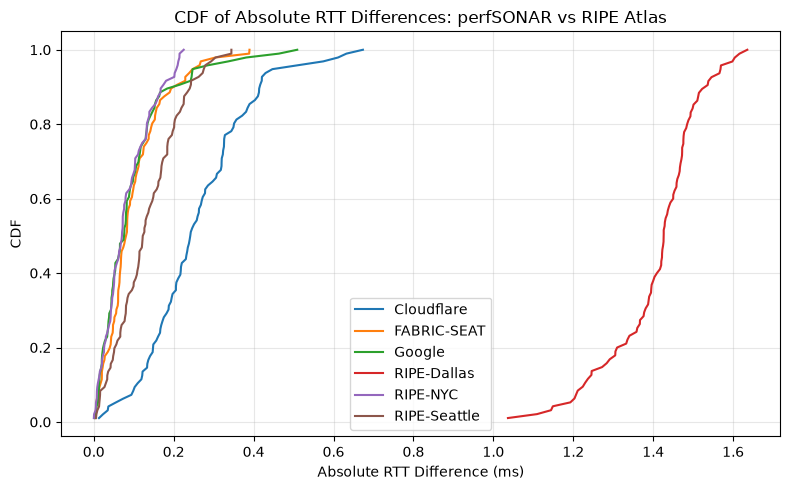

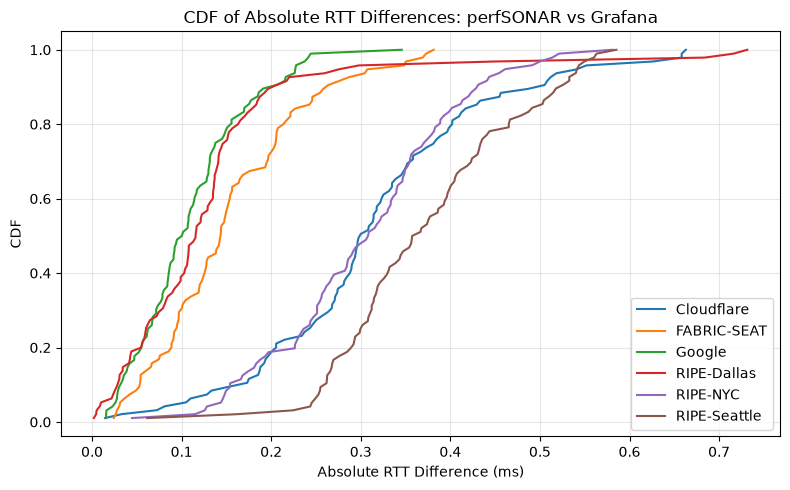

In [4]:
# ============================================================
# STEP 4 — CDF OF ABSOLUTE RTT DIFFERENCES
# ============================================================

import matplotlib.pyplot as plt


def plot_cdf(df, title):

    plt.figure(figsize=(8, 5))

    for target in sorted(df["target_name"].unique()):

        values = (
            df.loc[
                df["target_name"] == target,
                "absolute_difference_ms"
            ]
            .dropna()
            .sort_values()
            .to_numpy()
        )

        if len(values) == 0:
            continue

        y = np.arange(
            1,
            len(values) + 1
        ) / len(values)

        plt.plot(
            values,
            y,
            label=target
        )

    plt.xlabel("Absolute RTT Difference (ms)")
    plt.ylabel("CDF")
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    plt.show()


plot_cdf(
    perf_vs_ripe,
    "CDF of Absolute RTT Differences: perfSONAR vs RIPE Atlas"
)

plot_cdf(
    perf_vs_grafana,
    "CDF of Absolute RTT Differences: perfSONAR vs Grafana"
)

In [5]:
# ============================================================
# STEP 5 — BLAND–ALTMAN AGREEMENT ANALYSIS
# ============================================================

def bland_altman_stats(df, comparison_name):

    out = df.copy()

    # Average of the two tools
    out["pair_mean_rtt_ms"] = (
        out["perfsonar_rtt_min_ms"]
        + out["other_rtt_min_ms"]
    ) / 2

    # Signed difference: perfSONAR - other tool
    out["difference_ms"] = (
        out["perfsonar_rtt_min_ms"]
        - out["other_rtt_min_ms"]
    )

    summary_rows = []

    for target, group in out.groupby("target_name"):

        diff = group["difference_ms"].dropna()

        bias = diff.mean()
        sd = diff.std(ddof=1)

        lower_loa = bias - 1.96 * sd
        upper_loa = bias + 1.96 * sd

        summary_rows.append({
            "comparison": comparison_name,
            "target_name": target,
            "matched_pairs": len(diff),
            "bias_ms": bias,
            "sd_difference_ms": sd,
            "lower_loa_ms": lower_loa,
            "upper_loa_ms": upper_loa
        })

    summary = pd.DataFrame(summary_rows)

    return out, summary


perf_vs_ripe_ba, ripe_ba_summary = bland_altman_stats(
    perf_vs_ripe,
    "perfSONAR vs RIPE Atlas"
)

perf_vs_grafana_ba, grafana_ba_summary = bland_altman_stats(
    perf_vs_grafana,
    "perfSONAR vs Grafana"
)

bland_altman_summary = pd.concat(
    [
        ripe_ba_summary,
        grafana_ba_summary
    ],
    ignore_index=True
)

display(
    bland_altman_summary.round(4)
)

,comparison,target_name,matched_pairs,bias_ms,sd_difference_ms,lower_loa_ms,upper_loa_ms
0,perfSONAR vs RIPE Atlas,Cloudflare,96,0.2553,0.1398,-0.0187,0.5292
1,perfSONAR vs RIPE Atlas,FABRIC-SEAT,96,-0.0397,0.1204,-0.2758,0.1964
2,perfSONAR vs RIPE Atlas,Google,96,-0.0786,0.1083,-0.2909,0.1337
3,perfSONAR vs RIPE Atlas,RIPE-Dallas,95,-1.4075,0.1153,-1.6335,-1.1816
4,perfSONAR vs RIPE Atlas,RIPE-NYC,96,0.0044,0.1023,-0.1961,0.2050
5,perfSONAR vs RIPE Atlas,RIPE-Seattle,96,0.1239,0.0959,-0.0641,0.3118
6,perfSONAR vs Grafana,Cloudflare,95,0.3148,0.1310,0.0581,0.5715
7,perfSONAR vs Grafana,FABRIC-SEAT,95,0.1493,0.0925,-0.0321,0.3306
8,perfSONAR vs Grafana,Google,96,0.1018,0.0753,-0.0458,0.2494
9,perfSONAR vs Grafana,RIPE-Dallas,95,-0.1039,0.1512,-0.4001,0.1924


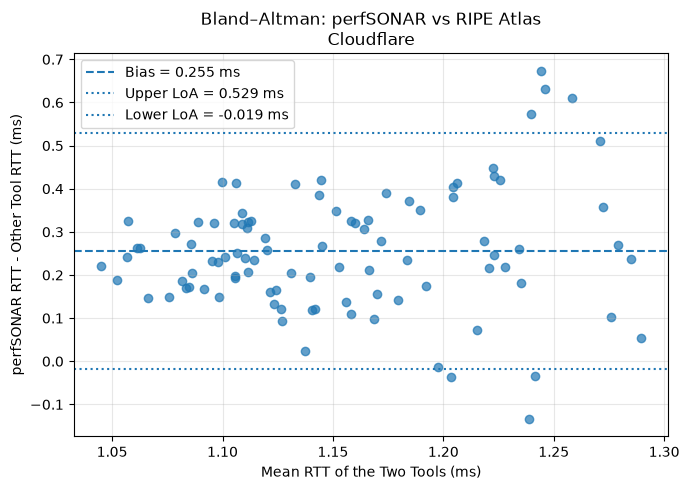

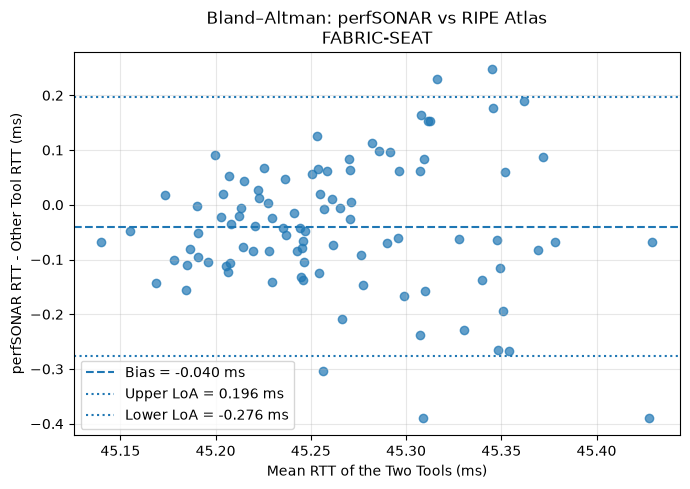

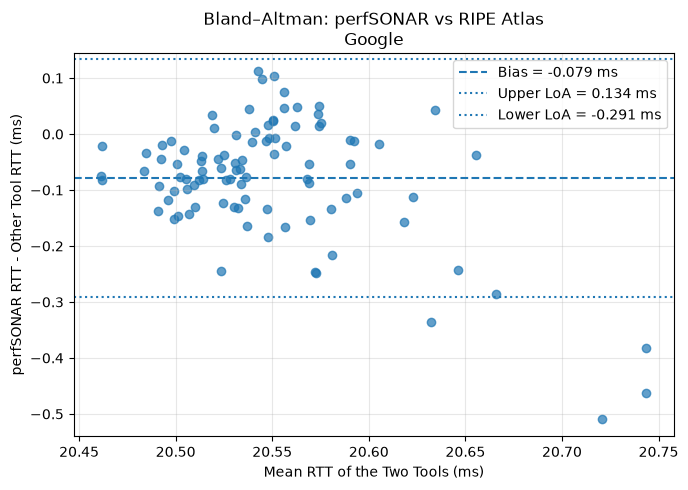

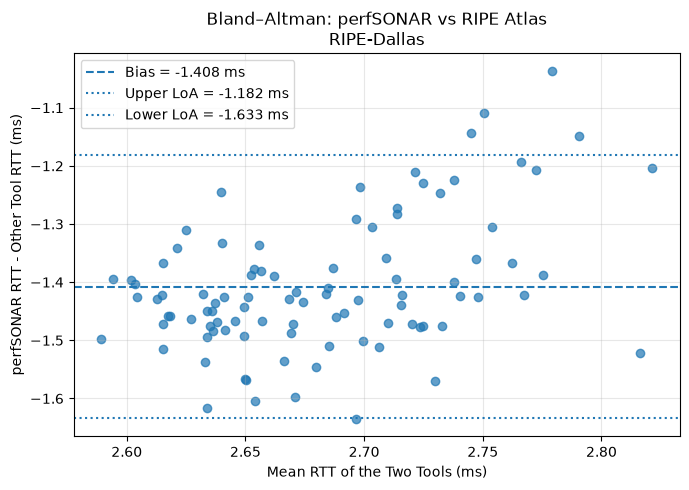

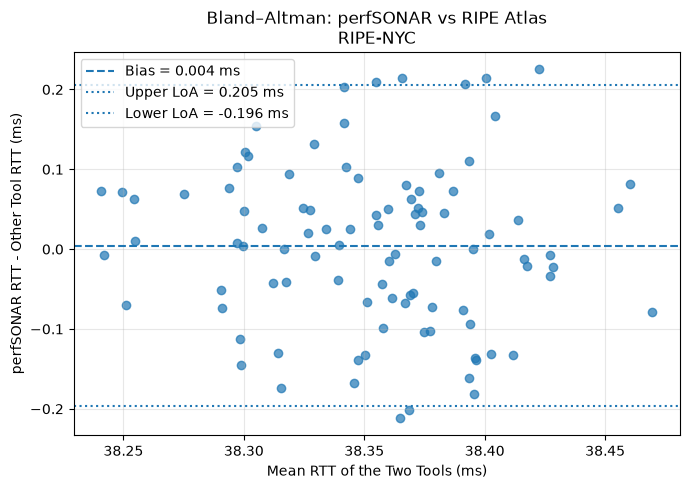

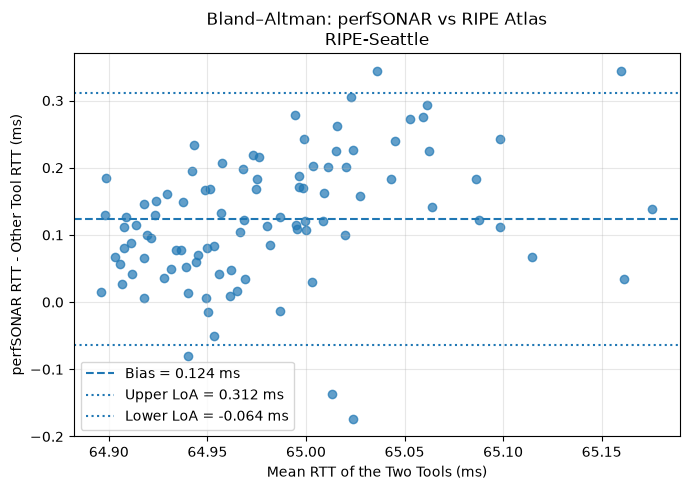

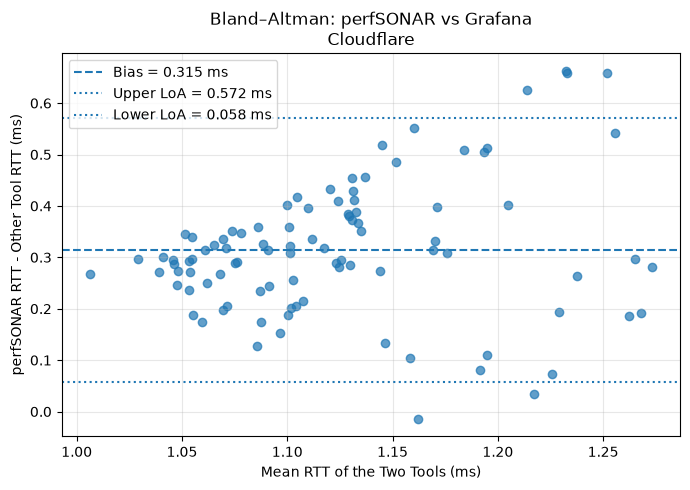

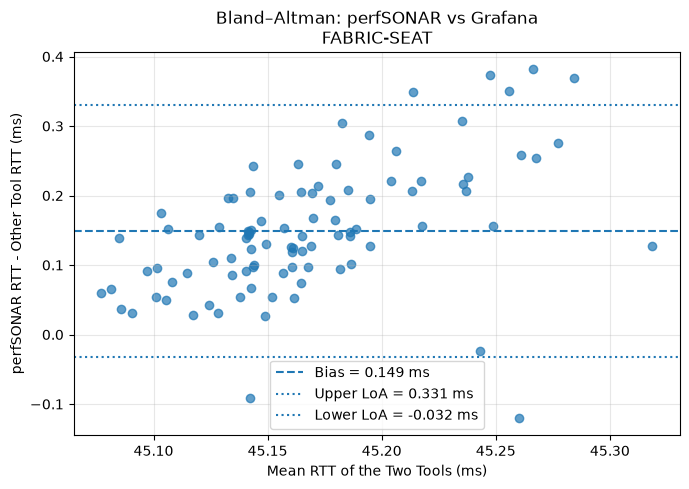

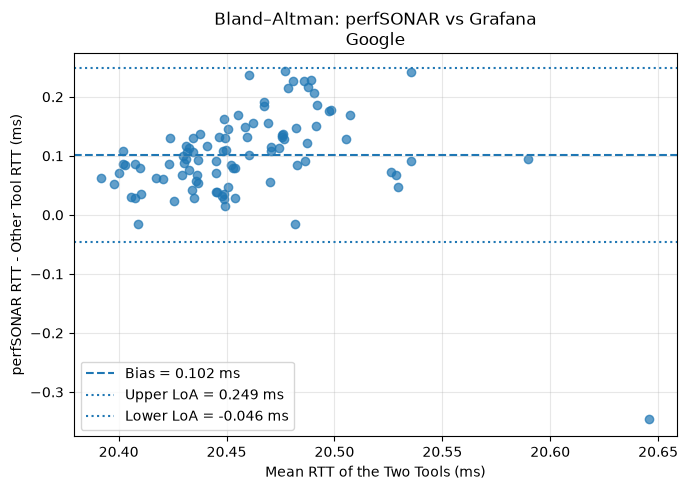

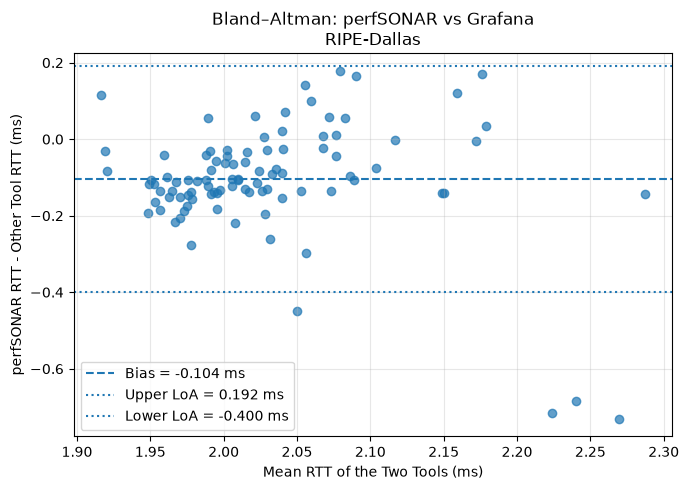

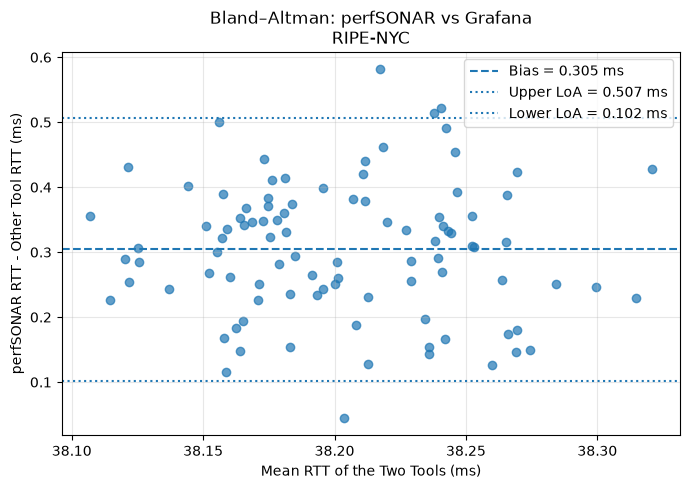

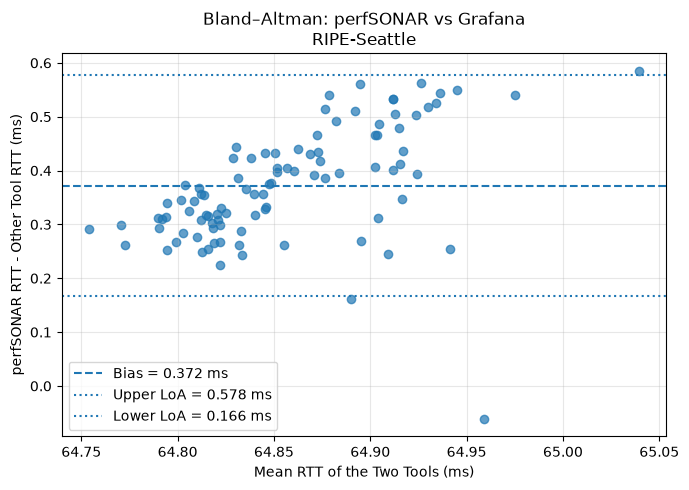

In [6]:
# ============================================================
# STEP 6 — BLAND–ALTMAN PLOTS
# ============================================================

import matplotlib.pyplot as plt


def plot_bland_altman(df, summary_df, comparison_name):

    targets = sorted(df["target_name"].unique())

    for target in targets:

        subset = df[
            df["target_name"] == target
        ].copy()

        stats = summary_df[
            summary_df["target_name"] == target
        ].iloc[0]

        bias = stats["bias_ms"]
        lower = stats["lower_loa_ms"]
        upper = stats["upper_loa_ms"]

        plt.figure(figsize=(7, 5))

        plt.scatter(
            subset["pair_mean_rtt_ms"],
            subset["difference_ms"],
            alpha=0.7
        )

        plt.axhline(
            bias,
            linestyle="--",
            label=f"Bias = {bias:.3f} ms"
        )

        plt.axhline(
            upper,
            linestyle=":",
            label=f"Upper LoA = {upper:.3f} ms"
        )

        plt.axhline(
            lower,
            linestyle=":",
            label=f"Lower LoA = {lower:.3f} ms"
        )

        plt.xlabel("Mean RTT of the Two Tools (ms)")
        plt.ylabel("perfSONAR RTT - Other Tool RTT (ms)")

        plt.title(
            f"Bland–Altman: {comparison_name}\n{target}"
        )

        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.tight_layout()

        plt.show()


plot_bland_altman(
    perf_vs_ripe_ba,
    ripe_ba_summary,
    "perfSONAR vs RIPE Atlas"
)

plot_bland_altman(
    perf_vs_grafana_ba,
    grafana_ba_summary,
    "perfSONAR vs Grafana"
)

In [9]:
# ============================================================
# STEP 7 — CHECK FOR PROPORTIONAL BIAS
# NumPy-only version (no SciPy required)
# ============================================================

def proportional_bias_summary(df, comparison_name):

    rows = []

    for target, group in df.groupby("target_name"):

        clean = group[
            [
                "pair_mean_rtt_ms",
                "difference_ms"
            ]
        ].dropna()

        x = clean["pair_mean_rtt_ms"].to_numpy()
        y = clean["difference_ms"].to_numpy()

        # Linear regression: y = slope*x + intercept
        slope, intercept = np.polyfit(x, y, 1)

        # Pearson correlation
        r_value = np.corrcoef(x, y)[0, 1]

        rows.append({
            "comparison": comparison_name,
            "target_name": target,
            "matched_pairs": len(clean),
            "slope": slope,
            "intercept": intercept,
            "r_value": r_value
        })

    return pd.DataFrame(rows)


ripe_proportional_bias = proportional_bias_summary(
    perf_vs_ripe_ba,
    "perfSONAR vs RIPE Atlas"
)

grafana_proportional_bias = proportional_bias_summary(
    perf_vs_grafana_ba,
    "perfSONAR vs Grafana"
)

proportional_bias_results = pd.concat(
    [
        ripe_proportional_bias,
        grafana_proportional_bias
    ],
    ignore_index=True
)

display(
    proportional_bias_results.round(5)
)

,comparison,target_name,matched_pairs,slope,intercept,r_value
0,perfSONAR vs RIPE Atlas,Cloudflare,96,0.33117,-0.12672,0.14916
1,perfSONAR vs RIPE Atlas,FABRIC-SEAT,96,-0.03610,1.59409,-0.01809
2,perfSONAR vs RIPE Atlas,Google,96,-0.97054,19.86477,-0.47904
3,perfSONAR vs RIPE Atlas,RIPE-Dallas,95,0.94761,-3.94889,0.44123
4,perfSONAR vs RIPE Atlas,RIPE-NYC,96,-0.12981,4.98302,-0.06238
5,perfSONAR vs RIPE Atlas,RIPE-Seattle,96,0.55452,-35.90947,0.35659
6,perfSONAR vs Grafana,Cloudflare,95,0.44847,-0.18940,0.21926
7,perfSONAR vs Grafana,FABRIC-SEAT,95,0.94348,-42.46573,0.51838
8,perfSONAR vs Grafana,Google,96,-0.00582,0.22079,-0.00311
9,perfSONAR vs Grafana,RIPE-Dallas,95,-0.41430,0.73718,-0.20327


In [10]:
# ============================================================
# STEP 8 — INTERPRETABLE PROPORTIONAL-BIAS EFFECT SIZE
# How much does the fitted tool difference change across
# the RTT range actually observed for each target?
# ============================================================

def proportional_bias_effect(df, comparison_name):

    rows = []

    for target, group in df.groupby("target_name"):

        clean = group[
            [
                "pair_mean_rtt_ms",
                "difference_ms"
            ]
        ].dropna()

        x = clean["pair_mean_rtt_ms"].to_numpy()
        y = clean["difference_ms"].to_numpy()

        slope, intercept = np.polyfit(x, y, 1)
        r_value = np.corrcoef(x, y)[0, 1]

        x_min = x.min()
        x_max = x.max()
        x_range = x_max - x_min

        fitted_change = slope * x_range

        rows.append({
            "comparison": comparison_name,
            "target_name": target,
            "matched_pairs": len(clean),
            "mean_rtt_min_ms": x_min,
            "mean_rtt_max_ms": x_max,
            "observed_rtt_range_ms": x_range,
            "slope": slope,
            "r_value": r_value,
            "fitted_difference_change_ms": fitted_change
        })

    return pd.DataFrame(rows)


ripe_bias_effect = proportional_bias_effect(
    perf_vs_ripe_ba,
    "perfSONAR vs RIPE Atlas"
)

grafana_bias_effect = proportional_bias_effect(
    perf_vs_grafana_ba,
    "perfSONAR vs Grafana"
)

proportional_bias_effects = pd.concat(
    [
        ripe_bias_effect,
        grafana_bias_effect
    ],
    ignore_index=True
)

display(
    proportional_bias_effects.round(4)
)

,comparison,target_name,matched_pairs,mean_rtt_min_ms,mean_rtt_max_ms,observed_rtt_range_ms,slope,r_value,fitted_difference_change_ms
0,perfSONAR vs RIPE Atlas,Cloudflare,96,1.0448,1.2896,0.2448,0.3312,0.1492,0.0811
1,perfSONAR vs RIPE Atlas,FABRIC-SEAT,96,45.1399,45.4294,0.2894,-0.0361,-0.0181,-0.0104
2,perfSONAR vs RIPE Atlas,Google,96,20.4613,20.7437,0.2824,-0.9705,-0.4790,-0.2741
3,perfSONAR vs RIPE Atlas,RIPE-Dallas,95,2.5892,2.8215,0.2322,0.9476,0.4412,0.2201
4,perfSONAR vs RIPE Atlas,RIPE-NYC,96,38.2408,38.4696,0.2289,-0.1298,-0.0624,-0.0297
5,perfSONAR vs RIPE Atlas,RIPE-Seattle,96,64.8961,65.1758,0.2796,0.5545,0.3566,0.1551
6,perfSONAR vs Grafana,Cloudflare,95,1.0062,1.2732,0.2670,0.4485,0.2193,0.1197
7,perfSONAR vs Grafana,FABRIC-SEAT,95,45.0771,45.3186,0.2416,0.9435,0.5184,0.2279
8,perfSONAR vs Grafana,Google,96,20.3918,20.6459,0.2541,-0.0058,-0.0031,-0.0015
9,perfSONAR vs Grafana,RIPE-Dallas,95,1.9163,2.2872,0.3709,-0.4143,-0.2033,-0.1537


In [11]:
# ============================================================
# STEP 9 — SAVE NEW AGREEMENT-ANALYSIS TABLES
# ============================================================

from pathlib import Path

FINAL_STATS_DIR = Path(
    ""
    "cross_tool_analysis/final_statistics"
)

FINAL_STATS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Save paired RTT summary
paired_file = (
    FINAL_STATS_DIR
    / "paired_rtt_agreement_summary.csv"
)

paired_rtt_summary.to_csv(
    paired_file,
    index=False
)

# Save Bland–Altman summary
ba_file = (
    FINAL_STATS_DIR
    / "bland_altman_summary.csv"
)

bland_altman_summary.to_csv(
    ba_file,
    index=False
)

# Save proportional-bias effect summary
bias_effect_file = (
    FINAL_STATS_DIR
    / "proportional_bias_effects.csv"
)

proportional_bias_effects.to_csv(
    bias_effect_file,
    index=False
)

print("Saved:")
print(paired_file)
print(ba_file)
print(bias_effect_file)

print("\nShapes:")
print("Paired RTT:", paired_rtt_summary.shape)
print("Bland–Altman:", bland_altman_summary.shape)
print("Proportional bias:", proportional_bias_effects.shape)

Saved:
/home/fabric/work/network_measurement_case_study/cross_tool_analysis/final_statistics/paired_rtt_agreement_summary.csv
/home/fabric/work/network_measurement_case_study/cross_tool_analysis/final_statistics/bland_altman_summary.csv
/home/fabric/work/network_measurement_case_study/cross_tool_analysis/final_statistics/proportional_bias_effects.csv

Shapes:
Paired RTT: (12, 8)
Bland–Altman: (12, 7)
Proportional bias: (12, 9)


In [12]:
# ============================================================
# STEP 10 — CREATE FIGURES FOLDER
# ============================================================

FIGURES_DIR = Path(
    ""
    "cross_tool_analysis/figures"
)

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Figures folder:")
print(FIGURES_DIR)

Figures folder:
/home/fabric/work/network_measurement_case_study/cross_tool_analysis/figures


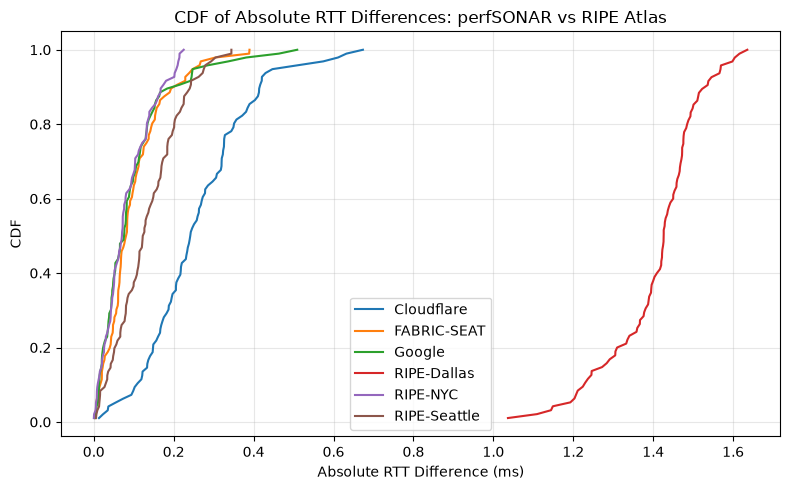

Saved: /home/fabric/work/network_measurement_case_study/cross_tool_analysis/figures/cdf_perfsonar_vs_ripe_atlas.png


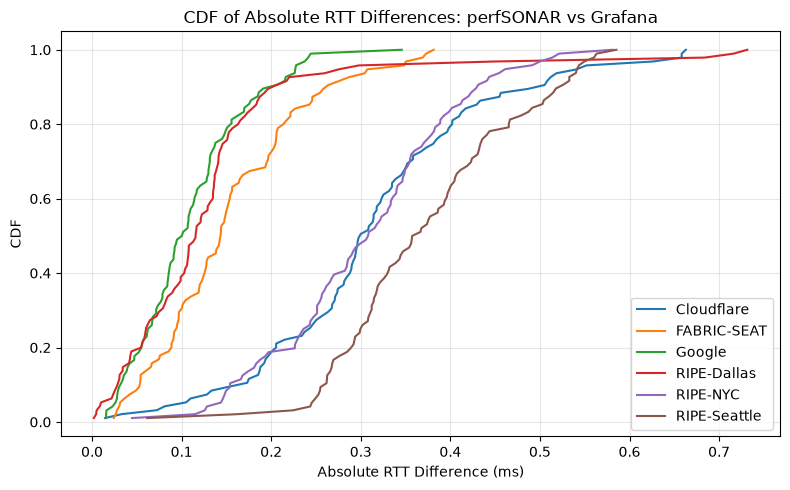

Saved: /home/fabric/work/network_measurement_case_study/cross_tool_analysis/figures/cdf_perfsonar_vs_grafana.png


In [13]:
# ============================================================
# STEP 11 — SAVE CDF FIGURES
# ============================================================

def save_cdf(df, title, filename):

    plt.figure(figsize=(8, 5))

    for target in sorted(df["target_name"].unique()):

        values = (
            df.loc[
                df["target_name"] == target,
                "absolute_difference_ms"
            ]
            .dropna()
            .sort_values()
            .to_numpy()
        )

        if len(values) == 0:
            continue

        y = np.arange(
            1,
            len(values) + 1
        ) / len(values)

        plt.plot(
            values,
            y,
            label=target
        )

    plt.xlabel("Absolute RTT Difference (ms)")
    plt.ylabel("CDF")
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    output_file = FIGURES_DIR / filename

    plt.savefig(
        output_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", output_file)


save_cdf(
    perf_vs_ripe,
    "CDF of Absolute RTT Differences: perfSONAR vs RIPE Atlas",
    "cdf_perfsonar_vs_ripe_atlas.png"
)

save_cdf(
    perf_vs_grafana,
    "CDF of Absolute RTT Differences: perfSONAR vs Grafana",
    "cdf_perfsonar_vs_grafana.png"
)

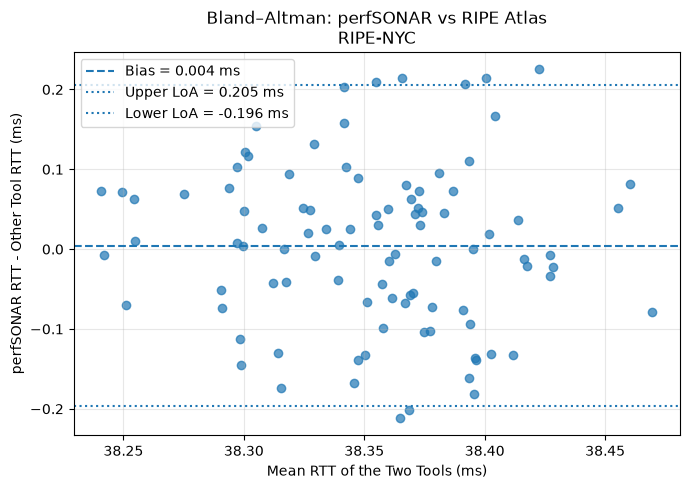

Saved: /home/fabric/work/network_measurement_case_study/cross_tool_analysis/figures/bland_altman_perf_vs_ripe_nyc.png


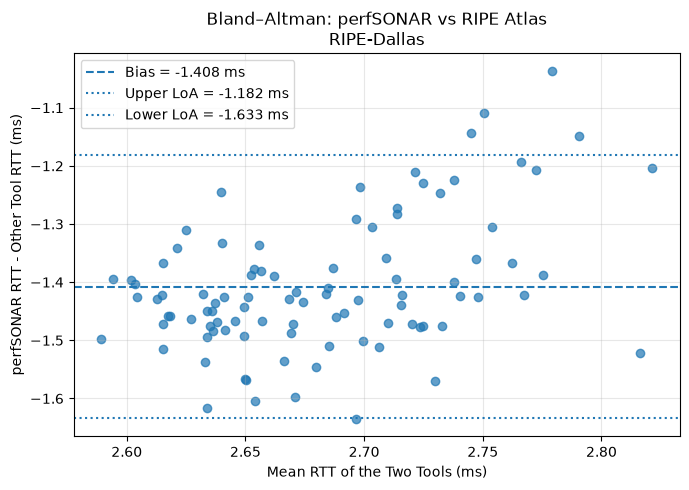

Saved: /home/fabric/work/network_measurement_case_study/cross_tool_analysis/figures/bland_altman_perf_vs_ripe_dallas.png


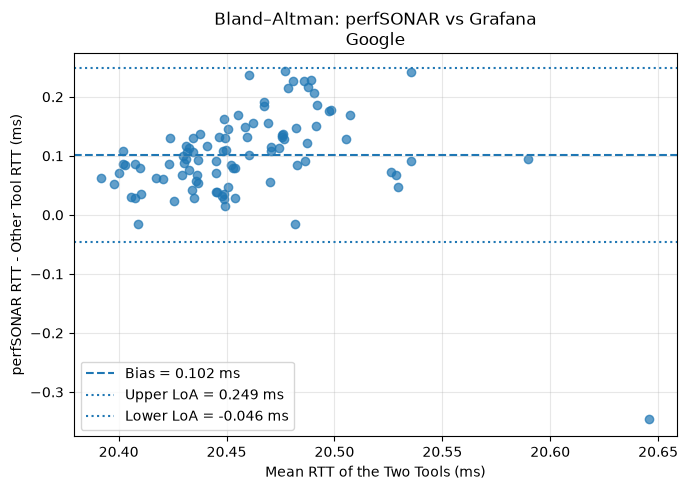

Saved: /home/fabric/work/network_measurement_case_study/cross_tool_analysis/figures/bland_altman_perf_vs_grafana_google.png


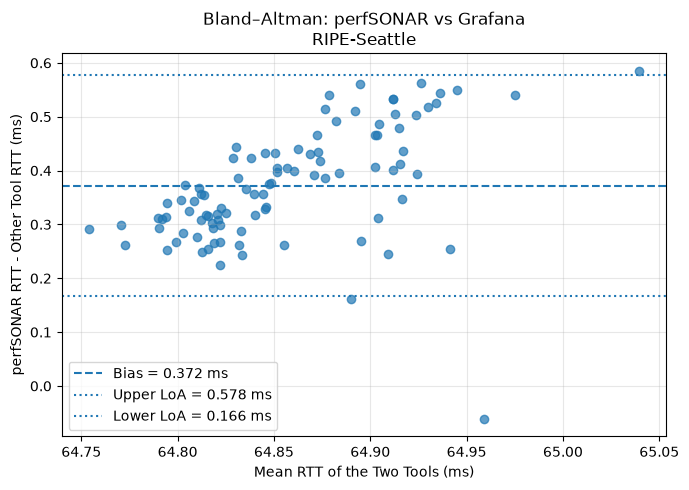

Saved: /home/fabric/work/network_measurement_case_study/cross_tool_analysis/figures/bland_altman_perf_vs_grafana_ripe_seattle.png


In [14]:
# ============================================================
# STEP 12 — SAVE REPRESENTATIVE BLAND–ALTMAN FIGURES
# ============================================================

def save_bland_altman_plot(
    df,
    summary_df,
    comparison_name,
    target_name,
    filename
):

    subset = df[
        df["target_name"] == target_name
    ].copy()

    stats = summary_df[
        summary_df["target_name"] == target_name
    ].iloc[0]

    bias = stats["bias_ms"]
    lower = stats["lower_loa_ms"]
    upper = stats["upper_loa_ms"]

    plt.figure(figsize=(7, 5))

    plt.scatter(
        subset["pair_mean_rtt_ms"],
        subset["difference_ms"],
        alpha=0.7
    )

    plt.axhline(
        bias,
        linestyle="--",
        label=f"Bias = {bias:.3f} ms"
    )

    plt.axhline(
        upper,
        linestyle=":",
        label=f"Upper LoA = {upper:.3f} ms"
    )

    plt.axhline(
        lower,
        linestyle=":",
        label=f"Lower LoA = {lower:.3f} ms"
    )

    plt.xlabel("Mean RTT of the Two Tools (ms)")
    plt.ylabel("perfSONAR RTT - Other Tool RTT (ms)")

    plt.title(
        f"Bland–Altman: {comparison_name}\n{target_name}"
    )

    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    output_file = FIGURES_DIR / filename

    plt.savefig(
        output_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", output_file)


# perfSONAR vs RIPE Atlas
save_bland_altman_plot(
    perf_vs_ripe_ba,
    ripe_ba_summary,
    "perfSONAR vs RIPE Atlas",
    "RIPE-NYC",
    "bland_altman_perf_vs_ripe_nyc.png"
)

save_bland_altman_plot(
    perf_vs_ripe_ba,
    ripe_ba_summary,
    "perfSONAR vs RIPE Atlas",
    "RIPE-Dallas",
    "bland_altman_perf_vs_ripe_dallas.png"
)

# perfSONAR vs Grafana
save_bland_altman_plot(
    perf_vs_grafana_ba,
    grafana_ba_summary,
    "perfSONAR vs Grafana",
    "Google",
    "bland_altman_perf_vs_grafana_google.png"
)

save_bland_altman_plot(
    perf_vs_grafana_ba,
    grafana_ba_summary,
    "perfSONAR vs Grafana",
    "RIPE-Seattle",
    "bland_altman_perf_vs_grafana_ripe_seattle.png"
)

In [15]:
print("Saved figures:")
for f in sorted(FIGURES_DIR.glob("*.png")):
    print(f.name)

Saved figures:
bland_altman_perf_vs_grafana_google.png
bland_altman_perf_vs_grafana_ripe_seattle.png
bland_altman_perf_vs_ripe_dallas.png
bland_altman_perf_vs_ripe_nyc.png
cdf_perfsonar_vs_grafana.png
cdf_perfsonar_vs_ripe_atlas.png


# Tool Methodology and Feature Comparison

The three platforms are all active-measurement systems, but they differ in deployment model, scheduling, measurement control, available metrics, and intended use. These methodological differences help explain small systematic offsets and path-level differences observed in the quantitative analysis.

In [16]:
# ============================================================
# STEP 13 — TOOL METHODOLOGY / FEATURE COMPARISON
# ============================================================

tool_feature_comparison = pd.DataFrame([
    {
        "feature": "Primary role",
        "perfSONAR": "Scientific / research network measurement",
        "RIPE Atlas": "Distributed Internet measurement platform",
        "Grafana Synthetic Monitoring": "Continuous synthetic / operational monitoring"
    },
    {
        "feature": "Measurement source",
        "perfSONAR": "Researcher-controlled FABRIC endpoint",
        "RIPE Atlas": "RIPE Atlas software/public probe",
        "Grafana Synthetic Monitoring": "Private probe deployed in FABRIC"
    },
    {
        "feature": "Source control",
        "perfSONAR": "High",
        "RIPE Atlas": "Moderate",
        "Grafana Synthetic Monitoring": "High with private probe"
    },
    {
        "feature": "Ping / RTT",
        "perfSONAR": "Yes",
        "RIPE Atlas": "Yes",
        "Grafana Synthetic Monitoring": "Yes"
    },
    {
        "feature": "Traceroute",
        "perfSONAR": "Yes",
        "RIPE Atlas": "Yes",
        "Grafana Synthetic Monitoring": "Yes"
    },
    {
        "feature": "Throughput testing",
        "perfSONAR": "Yes",
        "RIPE Atlas": "No",
        "Grafana Synthetic Monitoring": "No"
    },
    {
        "feature": "Packet-loss measurement",
        "perfSONAR": "Yes",
        "RIPE Atlas": "Yes",
        "Grafana Synthetic Monitoring": "Yes"
    },
    {
        "feature": "Path-level detail",
        "perfSONAR": "Detailed",
        "RIPE Atlas": "Detailed",
        "Grafana Synthetic Monitoring": "Operational / monitoring oriented"
    },
    {
        "feature": "Scheduling",
        "perfSONAR": "pScheduler / pSConfig",
        "RIPE Atlas": "RIPE Atlas measurement scheduler",
        "Grafana Synthetic Monitoring": "Synthetic-check interval"
    },
    {
        "feature": "Typical deployment effort",
        "perfSONAR": "Higher",
        "RIPE Atlas": "Lower to moderate",
        "Grafana Synthetic Monitoring": "Moderate"
    },
    {
        "feature": "Historical data access",
        "perfSONAR": "OpenSearch / archive backend",
        "RIPE Atlas": "REST API / downloadable results",
        "Grafana Synthetic Monitoring": "Prometheus-compatible metrics / API"
    },
    {
        "feature": "Best fit in this study",
        "perfSONAR": "Focal research measurement platform",
        "RIPE Atlas": "Independent Internet measurement comparison",
        "Grafana Synthetic Monitoring": "Continuous synthetic monitoring comparison"
    }
])

display(tool_feature_comparison)

,feature,perfSONAR,RIPE Atlas,Grafana Synthetic Monitoring
0,Primary role,Scientific / research network measurement,Distributed Internet measurement platform,Continuous synthetic / operational monitoring
1,Measurement source,Researcher-controlled FABRIC endpoint,RIPE Atlas software/public probe,Private probe deployed in FABRIC
2,Source control,High,Moderate,High with private probe
3,Ping / RTT,Yes,Yes,Yes
4,Traceroute,Yes,Yes,Yes
5,Throughput testing,Yes,No,No
6,Packet-loss measurement,Yes,Yes,Yes
7,Path-level detail,Detailed,Detailed,Operational / monitoring oriented
8,Scheduling,pScheduler / pSConfig,RIPE Atlas measurement scheduler,Synthetic-check interval
9,Typical deployment effort,Higher,Lower to moderate,Moderate


In [17]:
feature_file = (
    FINAL_STATS_DIR
    / "tool_methodology_feature_comparison.csv"
)

tool_feature_comparison.to_csv(
    feature_file,
    index=False
)

print("Saved:")
print(feature_file)

Saved:
/home/fabric/work/network_measurement_case_study/cross_tool_analysis/final_statistics/tool_methodology_feature_comparison.csv


In [18]:
# ============================================================
# STEP 14 — FINAL ANALYSIS SUMMARY TABLE
# ============================================================

final_analysis_summary = pd.DataFrame([
    {
        "analysis_area": "RTT agreement",
        "main_finding": (
            "perfSONAR showed close RTT agreement with RIPE Atlas "
            "and Grafana for most targets."
        ),
        "evidence": (
            "Median absolute paired RTT differences were generally "
            "below 0.4 ms for most targets."
        )
    },
    {
        "analysis_area": "Systematic RTT offset",
        "main_finding": (
            "RIPE-Dallas showed a distinct perfSONAR–RIPE Atlas offset."
        ),
        "evidence": (
            "Bland–Altman bias = -1.408 ms; "
            "95% limits of agreement = -1.633 to -1.182 ms."
        )
    },
    {
        "analysis_area": "perfSONAR vs Grafana",
        "main_finding": (
            "Agreement remained close across all six targets."
        ),
        "evidence": (
            "Target-level biases ranged approximately from "
            "-0.104 ms to +0.372 ms."
        )
    },
    {
        "analysis_area": "Magnitude-dependent differences",
        "main_finding": (
            "A few targets showed mild proportional structure, "
            "but the absolute effect was small."
        ),
        "evidence": (
            "Fitted change in tool difference across the observed RTT "
            "range remained below about 0.3 ms."
        )
    },
    {
        "analysis_area": "Hop-count agreement",
        "main_finding": (
            "Median hop counts showed strong agreement for most targets."
        ),
        "evidence": (
            "Cloudflare, Google, RIPE-Dallas, and RIPE-Seattle "
            "showed matching median hop counts across tools."
        )
    },
    {
        "analysis_area": "Path variation",
        "main_finding": (
            "perfSONAR exposed more full-path variation than the "
            "other two tools."
        ),
        "evidence": (
            "Hop-count analysis showed that some full-path churn "
            "was likely interface/load-balancing variation rather "
            "than major structural route change."
        )
    },
    {
        "analysis_area": "Controlled delay",
        "main_finding": (
            "RIPE Atlas captured the +50 ms delay impairment."
        ),
        "evidence": (
            "Detection delay = 3 min 09 sec; measured RTT increase "
            "= 49.657 ms."
        )
    },
    {
        "analysis_area": "Controlled packet loss",
        "main_finding": (
            "perfSONAR detected the 20% loss condition earlier than Grafana."
        ),
        "evidence": (
            "perfSONAR detection = 7 min 12 sec; "
            "Grafana detection = 18 min 55 sec."
        )
    },
    {
        "analysis_area": "Recovery",
        "main_finding": (
            "perfSONAR showed the fastest observed recovery."
        ),
        "evidence": (
            "perfSONAR recovery = 3 min 50 sec; "
            "Grafana recovery = 17 min 18 sec."
        )
    }
])

display(final_analysis_summary)

,analysis_area,main_finding,evidence
0,RTT agreement,perfSONAR showed close RTT agreement with RIPE...,Median absolute paired RTT differences were ge...
1,Systematic RTT offset,RIPE-Dallas showed a distinct perfSONAR–RIPE A...,Bland–Altman bias = -1.408 ms; 95% limits of a...
2,perfSONAR vs Grafana,Agreement remained close across all six targets.,Target-level biases ranged approximately from ...
3,Magnitude-dependent differences,A few targets showed mild proportional structu...,Fitted change in tool difference across the ob...
4,Hop-count agreement,Median hop counts showed strong agreement for ...,"Cloudflare, Google, RIPE-Dallas, and RIPE-Seat..."
5,Path variation,perfSONAR exposed more full-path variation tha...,Hop-count analysis showed that some full-path ...
6,Controlled delay,RIPE Atlas captured the +50 ms delay impairment.,Detection delay = 3 min 09 sec; measured RTT i...
7,Controlled packet loss,perfSONAR detected the 20% loss condition earl...,perfSONAR detection = 7 min 12 sec; Grafana de...
8,Recovery,perfSONAR showed the fastest observed recovery.,perfSONAR recovery = 3 min 50 sec; Grafana rec...


In [19]:
final_summary_file = (
    FINAL_STATS_DIR
    / "final_analysis_summary.csv"
)

final_analysis_summary.to_csv(
    final_summary_file,
    index=False
)

print("Saved:")
print(final_summary_file)

Saved:
/home/fabric/work/network_measurement_case_study/cross_tool_analysis/final_statistics/final_analysis_summary.csv


# Final Cross-Tool Conclusions

The comparative case study evaluated perfSONAR, RIPE Atlas, and Grafana Synthetic Monitoring using a common FABRIC Dallas site-level environment, common IPv6 destinations, and a shared 24-hour normal-condition observation window.

## RTT Agreement

The three platforms showed close RTT agreement for most destinations. Paired RTT analysis and Bland–Altman analysis showed that most inter-tool differences were small, generally within fractions of a millisecond.

A notable exception was the RIPE-Dallas destination, where perfSONAR and RIPE Atlas showed a systematic offset of approximately 1.4 ms. This demonstrates why agreement analysis is more informative than relying only on correlation.

Because RTT values were highly stable during the normal-condition experiment, Pearson correlation was often low even when the absolute differences between platforms were small. Therefore, low correlation in this study should not be interpreted as poor measurement agreement.

## Path and Hop-Count Behavior

Median traceroute hop counts agreed strongly across most destinations. However, full-path representations showed more variation, particularly in perfSONAR measurements.

In several cases, path changes occurred without corresponding hop-count changes, suggesting that some observed path variation may reflect load balancing or different responding router interfaces rather than major structural route changes.

Per-hop RTT analysis also showed that intermediate-hop response times should not be interpreted as additive link delays because routers may deprioritize ICMP responses.

## Controlled Network Impairment

A controlled impairment experiment was conducted on the FABRIC-SEAT target using Linux `tc netem`.

During the +50 ms delay experiment, RIPE Atlas captured the impairment and measured an RTT increase of approximately 49.7 ms. The shorter delay interval occurred between scheduled measurements for perfSONAR and Grafana, so those tools did not capture that impairment during the experiment.

During the 20% packet-loss experiment, perfSONAR detected packet loss after approximately 7 minutes, while Grafana detected it after approximately 19 minutes. RIPE Atlas did not observe packet loss in its small packet samples during this interval.

After the impairment was removed, perfSONAR showed the fastest observed recovery, followed by Grafana.

## Overall Finding

The three platforms generally produced consistent latency and path-level observations under normal conditions, but their scheduling intervals, packet counts, measurement implementations, and deployment models affected how quickly transient network conditions were observed.

The results show that the platforms are complementary rather than interchangeable. perfSONAR provides extensive researcher-controlled network measurement capabilities, RIPE Atlas provides an independent Internet measurement perspective, and Grafana Synthetic Monitoring provides continuous operational monitoring.

Together with the completed perfSONAR archive-analysis extensions, the study demonstrates both automated analysis of perfSONAR measurements and a broader cross-platform evaluation of network measurement behavior.